# EBIT Spectral Fitting — Method Comparison
## Chi-squared vs Cash  ·  Bin-integrated vs Point-evaluated  ·  F-test vs ΔC profile

Fits **5 Gaussians + flat background** to the EBIT tungsten spectrum.
All Gaussians share a single common width `sigma` (instrument resolution).
Line strengths are parameterised by **area** (total counts under the Gaussian).

| Fit label | Statistic | Model | CI method |
|---|---|---|---|
| **chi2_int** | Chi-squared | Bin-integrated | F-test + Δχ² profile |
| **chi2_pt** | Chi-squared | Point-evaluated | F-test |
| **cash_int** | Cash (Poisson) | Bin-integrated | ΔC profile |
| **cash_pt** | Cash (Poisson) | Point-evaluated | ΔC profile |

**Shared sigma**: physically motivated — all lines have the same instrumental broadening.  
Reduces free parameters from 16 → 12 (5 areas + 5 centres + 1 sigma + 1 background).

**Area parameterisation**:  area = total photon counts in each line, directly comparable
across bin-integrated and point-evaluated models without conversion.


## 1. Imports

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.special import erf
from scipy.stats import chi2 as chi2_dist
from lmfit import Parameters, Minimizer, conf_interval, printfuncs
import math, warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
print("Imports OK")


Imports OK


## 2. Load data

In [ ]:
load_w = False

if load_w == False:
    # data_fp = r"C:\Users\elyse\Downloads\Python\PSFC\XRS_fitting\example_data\spec_Ar.txt"
    # ecs_data = pd.read_csv(data_fp)
    lam, counts, err = np.loadtxt("../example_data/spec_Ca.txt", skiprows=1, unpack=True)
    # ecs_data = pd.DataFrame({"lambda [mAA]": _binlow_eV, "counts  [arb]": _counts, "err [arb]": err})
    # display(ecs_data)

    # 141 bins: binlow[i], binhigh[i] = binlow[i]+1
    # binhigh    = binlow + 1.0 # why is it +1? unit might need to be changed

    # In this implementation, the bin edges are defined as the midpoints between the bin centers. The first and last bins are extended to ensure that all data points are included within the bins.
    bincenters = lam
    mid = 0.5 * (lam[1:] + lam[:-1])            # edges between neighbours
    binlow = np.concatenate(([lam[0]  - (mid[0]  - lam[0])],  mid))
    binhigh = np.concatenate((mid, [lam[-1] + (lam[-1] - mid[-1])]))
    binwidths = binhigh - binlow                    
    observed = counts
    yerr = err
    # bincenters = binlow + 0.5

    assert len(binlow) == len(observed), "Length mismatch!"
    print(f"Bins         : {len(observed)}")
    print(f"Energy range : {binlow[0]:.0f}  to  {binhigh[-1]:.0f} eV")
    print(f"Total counts : {observed.sum():.0f}")
    print(f"Mean / bin   : {observed.mean():.1f}")
    print(f"Min  / bin   : {observed.min():.0f}")
else:
    # data_fp = r"C:\Users\elyse\Downloads\Python\PSFC\XRS_fitting\example_data\spec_Ar.txt"
    data_fp = r"C:\Users\elyse\Downloads\Python\PSFC\XRS_fitting\example_data\260421_W_EBIT_data.csv"
    ecs_data = pd.read_csv(data_fp)
    display(ecs_data)
    _binlow_eV = ecs_data["bin_low [eV]"].to_numpy(dtype=float)
    _counts    = ecs_data["[counts]"].to_numpy(dtype=float)

    # 141 bins: binlow[i], binhigh[i] = binlow[i]+1
    binlow     = np.array(_binlow_eV, dtype=float)
    binhigh    = binlow + 1.0
    bincenters = binlow + 0.5
    binwidths  = np.ones(len(binlow))
    observed   = np.array(_counts, dtype=float)
    yerr       = np.sqrt(np.where(observed <= 0, 1, observed))

    assert len(binlow) == len(observed), "Length mismatch!"
    print(f"Bins         : {len(observed)}")
    print(f"Energy range : {binlow[0]:.0f}  to  {binhigh[-1]:.0f} eV")
    print(f"Total counts : {observed.sum():.0f}")
    print(f"Mean / bin   : {observed.mean():.1f}")
    print(f"Min  / bin   : {observed.min():.0f}")

Bins         : 195
Energy range : 3162  to  3229 eV
Total counts : 14916
Mean / bin   : 76.5
Min  / bin   : 23


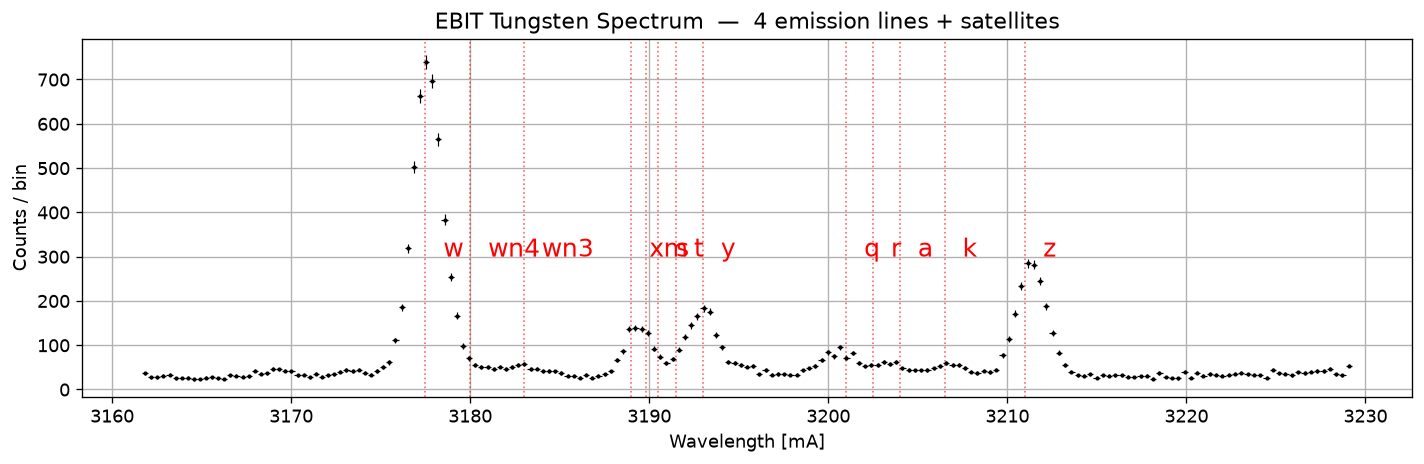

In [15]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.errorbar(bincenters, observed, yerr=yerr, xerr=binwidths/2,
            fmt='.', color='k', ms=3, elinewidth=0.7)
# ax.set_xlabel('Photon Energy [eV]')
ax.set_xlabel('Wavelength [mA]')
ax.set_ylabel('Counts / bin')
ax.set_title('EBIT Tungsten Spectrum  —  4 emission lines + satellites')
# min = np.array([3175, 3179, 3182, 3188, 3189, 3190.2, 3191, 3192, 3200, 3201, 3203, 3205, 3210])
mus = np.array([3177.5, 3180, 3183, 3189, 3189.8, 3190.5, 3191.5, 3193, 3201, 3202.5, 3204, 3206.5, 3211])
# max = np.array([3179, 3181, 3184, 3189.5, 3190, 3190.7, 3192.5, 3194, 3202, 3203, 3205, 3207.5, 3213])
label = ('w', 'wn4', 'wn3', 'x', 'm', 's', 't', 'y', 'q', 'r', 'a', 'k', 'z')

for i, e in enumerate(mus):
    ax.axvline(e, color='red', ls=':', alpha=0.6, lw=1)
    ax.text(e+1, 300, label[i], color='red', fontsize=15)
plt.tight_layout()
plt.grid()
plt.show()


## 3. Model functions

### Area parameterisation
Every Gaussian is parameterised by its **area** (total integrated counts):

$$\text{area}_i = \int_{-\infty}^{\infty} G_i(x)\,dx$$

For the **bin-integrated** model:
$$G_i^\text{int}(\text{low}, \text{high}) = \frac{\text{area}_i}{2}
\left[\text{erf}\!\left(\frac{\text{high}-\mu_i}{\sigma\sqrt{2}}\right) -
\text{erf}\!\left(\frac{\text{low}-\mu_i}{\sigma\sqrt{2}}\right)\right]$$

For the **point-evaluated** model (bin centre × bin width):
$$G_i^\text{pt}(x_c) = \frac{\text{area}_i}{\sigma\sqrt{2\pi}}
\exp\!\left[-\frac{(x_c-\mu_i)^2}{2\sigma^2}\right] \times \Delta x$$

Both models use **area** directly — no conversion needed in comparison tables.

### Shared sigma
All 5 Gaussians share one parameter `sigma` (instrumental FWHM / 2.355).
This is physically correct: all lines are broadened by the same instrument resolution.


In [16]:
def kahanSum(fa):
    s, c = 0.0, 0.0
    for f in fa:
        y = f-c; t = s+y; c = (t-s)-y; s = t
    return s

# ── Bin-integrated: area-normalised Gaussian integrated over bin ──────────
def int_gauss_area(bl, bh, area, mu, sigma):
    """Bin-integrated Gaussian. `area` = total counts in line.
    inputs: bin low, bin high, area is total counts in line, mu is mean, sigma is variance"""
    return 0.5 * area * (
        erf((bh - mu) / (sigma * np.sqrt(2))) -
        erf((bl - mu) / (sigma * np.sqrt(2))))

def int_bg(bl, bh, c):
    """ models background """
    return c * (np.asarray(bh) - np.asarray(bl))

# ── Point-evaluated: Gaussian evaluated at bin centre × bin width ─────────
def pt_gauss_area(xc, dx, area, mu, sigma):
    """Point-evaluated Gaussian. `area` = total counts in line.
    Uses area/(sigma*sqrt(2pi)) as peak amplitude, multiplied by bin width.
    """
    return (area / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((xc - mu)/sigma)**2) * dx

# ── 5-Gaussian + background models (shared sigma) ─────────────────────────
# def model5_int(bl, bh, ar1,mu1, ar2,mu2, ar3,mu3, ar4,mu4, ar5,mu5, sigma, bg):
#     """Bin-integrated model. sigma shared across all 5 lines."""
#     m = int_bg(bl, bh, bg)
#     for ar, mu in [(ar1,mu1),(ar2,mu2),(ar3,mu3),(ar4,mu4),(ar5,mu5)]:
#         m = m + int_gauss_area(bl, bh, ar, mu, sigma)
#     return m

# Handles N gaussian fittings and add to background 
def model_int(bl, bh, areas, mus, sigma, bg):
    """Bin-integrated model. N lines with shared sigma"""
    areas = np.asarray(areas)[:,None]
    mus = np.asarray(mus)[:,None]
    lines = int_gauss_area(bl, bh, areas, mus, sigma)
    m = int_bg(bl, bh, bg)
    return m + lines.sum(axis=0)


# def model5_pt(bc, bw, ar1,mu1, ar2,mu2, ar3,mu3, ar4,mu4, ar5,mu5, sigma, bg):
#     """Point-evaluated model. sigma shared across all 5 lines."""
#     m = bg * bw  # background: rate × bin_width
#     for ar, mu in [(ar1,mu1),(ar2,mu2),(ar3,mu3),(ar4,mu4),(ar5,mu5)]:
#         m = m + pt_gauss_area(bc, bw, ar, mu, sigma)
#     return m

def model_pt(bc, bw, areas, mus, sigma, bg):
    """Point-evaluated model. sigma shared across all N lines."""
    m = bg * bw  # background: rate × bin_width
    areas = np.asarray(areas)[:,None]
    mus = np.asarray(mus)[:,None]
    lines = pt_gauss_area(bc, bw, areas, mus, sigma)
    return m + lines.sum(axis=0)

# def eval_model(params, bl, bh, bc, bw, mode='int'):
#     p = params.valuesdict()
#     args = (p['ar1'],p['mu1'], p['ar2'],p['mu2'], p['ar3'],p['mu3'],
#             p['ar4'],p['mu4'], p['ar5'],p['mu5'], p['sigma'], p['bg'])
#     if mode == 'int':
#         return model_int(bl, bh, *args)
#     else:
#         return model_pt(bc, bw, *args)

def eval_model(params, bl, bh, bc, bw, mode='int'):
    p = params.valuesdict()
    n = sum(k.startswith('ar') for k in p)          # number of lines
    areas = np.array([p[f'ar{i}'] for i in range(1, n + 1)])
    mus   = np.array([p[f'mu{i}'] for i in range(1, n + 1)])
    if mode == 'int':
        return model_int(bl, bh, areas, mus, p['sigma'], p['bg'])
    return model_pt(bc, bw, areas, mus, p['sigma'], p['bg'])

print("Model functions defined.")
print("  Parameters: areas, mus (centers), sigma (shared), bg")


Model functions defined.
  Parameters: areas, mus (centers), sigma (shared), bg


In [17]:
# ── Cash statistic ────────────────────────────────────────────────────────
def cash_array_int(params, ydata, bl, bh):
    """Cash array for bin-integrated model."""
    model = eval_model(params, bl, bh, None, None, 'int')
    model = np.where(model <= 0, 1e-300, model)
    d     = np.where(ydata  <= 0, 1e-10,  ydata)
    return -2.0 * ((d - model) + d * (np.log(model) - np.log(d)))

def cash_array_pt(params, ydata, bl, bh, bc, bw):
    """Cash array for point-evaluated model."""
    model = eval_model(params, bl, bh, bc, bw, 'pt')
    model = np.where(model <= 0, 1e-300, model)
    d     = np.where(ydata  <= 0, 1e-10,  ydata)
    return -2.0 * ((d - model) + d * (np.log(model) - np.log(d)))

def cash_scalar_int(params, ydata, bl, bh):
    return kahanSum(cash_array_int(params, ydata, bl, bh))

def cash_scalar_pt(params, ydata, bl, bh, bc, bw):
    return kahanSum(cash_array_pt(params, ydata, bl, bh, bc, bw))

# ── Chi-squared residuals ─────────────────────────────────────────────────
def chisq_resid_int(params, ydata, bl, bh):
    model = eval_model(params, bl, bh, None, None, 'int')
    sigma = np.sqrt(np.where(ydata <= 0, 1, ydata))
    return (ydata - model) / sigma

def chisq_resid_pt(params, ydata, bl, bh, bc, bw):
    model = eval_model(params, bl, bh, bc, bw, 'pt')
    sigma = np.sqrt(np.where(ydata <= 0, 1, ydata))
    return (ydata - model) / sigma

# ── Signed Cash residuals for plotting ───────────────────────────────────
def signed_cash_resid_int(params, ydata, bl, bh):
    arr   = cash_array_int(params, ydata, bl, bh)
    model = eval_model(params, bl, bh, None, None, 'int')
    return np.sign(ydata - model) * np.sqrt(np.abs(arr))

def signed_cash_resid_pt(params, ydata, bl, bh, bc, bw):
    arr   = cash_array_pt(params, ydata, bl, bh, bc, bw)
    model = eval_model(params, bl, bh, bc, bw, 'pt')
    return np.sign(ydata - model) * np.sqrt(np.abs(arr))

print("Objective functions defined.")


Objective functions defined.


## 4. Initial parameters

**Shared sigma** is a single free parameter for the instrumental line width.
Initial guess: σ ≈ 1.5 eV (FWHM ≈ 3.5 eV), consistent with the spectrum.

**Areas** are initial guesses for total counts in each line above background.
Rough estimate: peak_height × sigma × sqrt(2π).


In [ ]:
# Guesses
peak_h = np.array([750, 20, 20, 140, 10, 10, 10, 200, 10, 10, 10, 10, 300])
# label = ('w', 'wn4', 'wn3', 'x', 'm', 's', 't', 'y', 'q', 'r', 'a', 'k', 'z')
mus = np.array([3177.5, 3180, 3183, 3189, 3189.8, 3190.5, 3191.5, 3193, 3201, 3202.5, 3204, 3206.5, 3211])
areas = peak_h * 1.5 * np.sqrt(2*np.pi)
mins_area = np.array([1000, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])
maxs_area = np.array([35000, 1000, 1000, 5000, 1000, 1000, 1000, 7000, 1000, 1000, 1000, 1000, 11000])
# mus = np.array([3177.5, 3189.5, 3193, 3211.5])
# mins_mu = np.array([3175, 3187, 3191, 3210])
mins_mu = np.array([3175, 3179, 3182, 3188, 3189, 3190.2, 3191, 3192, 3200, 3201, 3203, 3205, 3210])
maxs_mu = np.array([3179, 3181, 3184, 3189.5, 3190, 3190.7, 3192.5, 3194, 3202, 3203, 3205, 3207.5, 3213])
# maxs_mu = np.array([3179, 3190.8, 3195, 3213])


def make_params(areas, mus, mins_area, maxs_area, mins_mu, maxs_mu,
                sigma=1.5, sigma_min=0.3, sigma_max=5.0,
                bg=21.0, bg_min=5, bg_max=50):
    """
    Parameters for both bin-integrated and point-evaluated models.
    ar1-ar5  : area (total counts) for each Gaussian
    mu1-mu5  : line centre [eV]
    sigma    : shared Gaussian width [eV]  (FWHM = sigma * 2.355)
    bg       : flat background [counts/eV]
    """
    p = Parameters()
    # Areas (total counts above background)
    # Line centres [eV]
    for i, (a_i, m_i, a_min, a_max, m_min, m_max) in enumerate(zip(areas, mus, mins_area, maxs_area, mins_mu, maxs_mu), start=1):
        p.add(f'ar{i}', value=a_i, min=a_min, max=a_max)
        p.add(f'mu{i}', value=m_i, min=m_min, max=m_max)
    # Shared sigma [eV]
    p.add('sigma', value=sigma, min=sigma_min, max=sigma_max)
    # Background [counts/eV]
    p.add('bg', value=bg, min=bg_min, max=bg_max)
    return p

print("Parameters: ar1-ar5, mu1-mu5, sigma (shared), bg")
print(f"  Total free parameters: {sum(1 for p in make_params(areas, mus, mins_area, maxs_area, mins_mu, maxs_mu).values() if p.vary)}")
# print(f"  (vs 16 with independent sigmas)")


Parameters: ar1-ar5, mu1-mu5, sigma (shared), bg
  Total free parameters: 28


## 5. Run all four fits

| Fit | Statistic | Model | Notes |
|---|---|---|---|
| chi2_int | χ² leastsq | Bin-integrated | Correct model |
| chi2_pt  | χ² leastsq | Point-evaluated | Approx (bin centre × width) |
| cash_int | Cash | Bin-integrated | Correct model + stat |
| cash_pt  | Cash | Point-evaluated | Cash stat, approx model |


In [19]:
def fit_chisq(obj, params, fcn_args):
    """Nelder → leastsq. leastsq required for F-test conf_interval."""
    def sq(p, *a): 
        return np.sum(obj(p, *a)**2) #
    r1   = Minimizer(sq, params, fcn_args=fcn_args).minimize(method='nelder')
    mini = Minimizer(obj, r1.params, fcn_args=fcn_args)
    return mini, mini.minimize(method='leastsq')

def fit_cash(cash_fn, params, fcn_args):
    """Nelder → L-BFGS-B."""
    kw = dict(fcn_args=fcn_args, reduce_fcn=kahanSum)
    r1   = Minimizer(cash_fn, params, **kw).minimize(method='nelder')
    mini = Minimizer(cash_fn, r1.params, **kw)
    return mini, mini.minimize(method='lbfgsb')

# ── Fit 1: chi2 / bin-integrated ──────────────────────────────────────────
print("chi2-int  ...", end=' ', flush=True)
mini_ci, res_ci = fit_chisq(chisq_resid_int, make_params(areas, mus, mins_area, maxs_area, mins_mu, maxs_mu),
                             (observed, binlow, binhigh))
chi2_ci = res_ci.chisqr; dof_ci = res_ci.nfree
print(f"chi2/dof = {chi2_ci/dof_ci:.3f}")

# ── Fit 2: chi2 / point-evaluated ─────────────────────────────────────────
print("chi2-pt   ...", end=' ', flush=True)
mini_cp, res_cp = fit_chisq(chisq_resid_pt, make_params(areas, mus, mins_area, maxs_area, mins_mu, maxs_mu),
                             (observed, binlow, binhigh, bincenters, binwidths))
chi2_cp = res_cp.chisqr; dof_cp = res_cp.nfree
print(f"chi2/dof = {chi2_cp/dof_cp:.3f}")

# ── Fit 3: cash / bin-integrated ──────────────────────────────────────────
print("cash-int  ...", end=' ', flush=True)
mini_ca_int, res_ca_int = fit_cash(cash_array_int, make_params(areas, mus, mins_area, maxs_area, mins_mu, maxs_mu),
                                    (observed, binlow, binhigh))
C_int = cash_scalar_int(res_ca_int.params, observed, binlow, binhigh)
dof_ca_int = len(observed) - sum(p.vary for p in res_ca_int.params.values())
print(f"C/dof    = {C_int/dof_ca_int:.3f}")

# ── Fit 4: cash / point-evaluated ─────────────────────────────────────────
print("cash-pt   ...", end=' ', flush=True)
mini_ca_pt, res_ca_pt = fit_cash(cash_array_pt, make_params(areas, mus, mins_area, maxs_area, mins_mu, maxs_mu),
                                  (observed, binlow, binhigh, bincenters, binwidths))
C_pt  = cash_scalar_pt(res_ca_pt.params, observed, binlow, binhigh, bincenters, binwidths)
dof_ca_pt = len(observed) - sum(p.vary for p in res_ca_pt.params.values())
print(f"C/dof    = {C_pt/dof_ca_pt:.3f}")

print()
print("Summary:")
print(f"  chi2_int  chi2/dof = {chi2_ci/dof_ci:.4f}")
print(f"  chi2_pt   chi2/dof = {chi2_cp/dof_cp:.4f}")
print(f"  cash_int  C/dof    = {C_int/dof_ca_int:.4f}")
print(f"  cash_pt   C/dof    = {C_pt/dof_ca_pt:.4f}")


chi2-int  ... chi2/dof = 5.687
chi2-pt   ... chi2/dof = 5.737
cash-int  ... C/dof    = 7.714
cash-pt   ... C/dof    = 7.676

Summary:
  chi2_int  chi2/dof = 5.6873
  chi2_pt   chi2/dof = 5.7368
  cash_int  C/dof    = 7.7144
  cash_pt   C/dof    = 7.6763


### How do the symmetric error bars get computed?

`lmfit`'s `leastsq` uses the **Levenberg-Marquardt** algorithm, which builds a
numerical Jacobian $J_{ij} = \partial r_i / \partial \theta_j$ (derivative of
each weighted residual with respect to each parameter). From this it estimates
the covariance matrix:

$$\text{Cov} = \left(J^T J\right)^{-1} \times \frac{\chi^2}{\text{dof}}$$

The symmetric `stderr` on each parameter is $\sqrt{\text{Cov}_{ii}}$.
This is a **Gaussian / parabolic approximation** — it assumes the likelihood
surface is a perfect paraboloid near the minimum, giving symmetric errors.
The profile scanning in later cells finds the actual (possibly asymmetric)
likelihood contours.

### Why does `fit_chisq` use two minimisers?

```python
def fit_chisq(obj, params, fcn_args):
    def sq(p, *a): return np.sum(obj(p,*a)**2)      # sum-of-squares scalar
    r1   = Minimizer(sq,  params, ...).minimize(method='nelder')   # Stage 1
    mini = Minimizer(obj, r1.params, ...)                           # Stage 2
    return mini, mini.minimize(method='leastsq')
```

**Stage 1 — Nelder-Mead on `sq`:** Nelder-Mead is gradient-free and explores
broadly. It minimises the scalar sum-of-squares to find the right basin even
from a poor starting point.

**Stage 2 — `leastsq` from the Nelder solution:** `leastsq` needs the residual
*array* (not a scalar) to build the Jacobian for covariance estimation. It also
converges more precisely than Nelder-Mead. Starting from the Nelder result means
it's already in the right basin so it won't get lost.

**Why return `mini`?** `conf_interval` (F-test) needs the `Minimizer` object later
to refit the model at each profile grid point — it can't do that from the result alone.

### Where is sigma shared across all 5 Gaussians?

In `make_params()` there is **one** `sigma` entry — no `s1`, `s2`, etc.:
```python
p.add('sigma', value=1.5, min=0.3, max=5.0)   # single shared width
```
And in `model5_int()` / `model5_pt()` the **same** `sigma` is passed to every
Gaussian:
```python
for ar, mu in [(ar1,mu1), (ar2,mu2), (ar3,mu3), (ar4,mu4), (ar5,mu5)]:
    m += int_gauss_area(bl, bh, ar, mu, sigma)   # ← same sigma every time
```
The minimiser has 12 free parameters total: 5 areas + 5 centres + **1 sigma** + 1 background.


In [20]:
def hessian_stderr(result, stat_scalar_fn, fcn_args, eps_frac=1e-4):
    """Diagonal Hessian stderr from scalar stat surface (for grid sizing)."""
    p0 = result.params.copy()
    S0 = stat_scalar_fn(p0, *fcn_args)
    se = {}
    for name in [n for n in p0 if p0[n].vary]:
        v = p0[name].value
        h = max(abs(v)*eps_frac, 1e-4)
        pp = p0.copy(); pp[name].value = v + h
        pm = p0.copy(); pm[name].value = v - h
        d2 = (stat_scalar_fn(pp, *fcn_args) - 2*S0 +
              stat_scalar_fn(pm, *fcn_args)) / h**2
        se[name] = np.sqrt(2.0/d2) if d2 > 1e-12 else abs(v)*0.05
    return se

print("Cash Hessian stderr (cash_int) ...", end=' ', flush=True)
se_ca_int = hessian_stderr(res_ca_int, cash_scalar_int,
                            (observed, binlow, binhigh))
for n,s in se_ca_int.items(): res_ca_int.params[n].stderr = s
print("done")

print("Cash Hessian stderr (cash_pt)  ...", end=' ', flush=True)
se_ca_pt = hessian_stderr(res_ca_pt, cash_scalar_pt,
                           (observed, binlow, binhigh, bincenters, binwidths))
for n,s in se_ca_pt.items(): res_ca_pt.params[n].stderr = s
print("done")


Cash Hessian stderr (cash_int) ... done
Cash Hessian stderr (cash_pt)  ... done


## 6. Plot all four fits

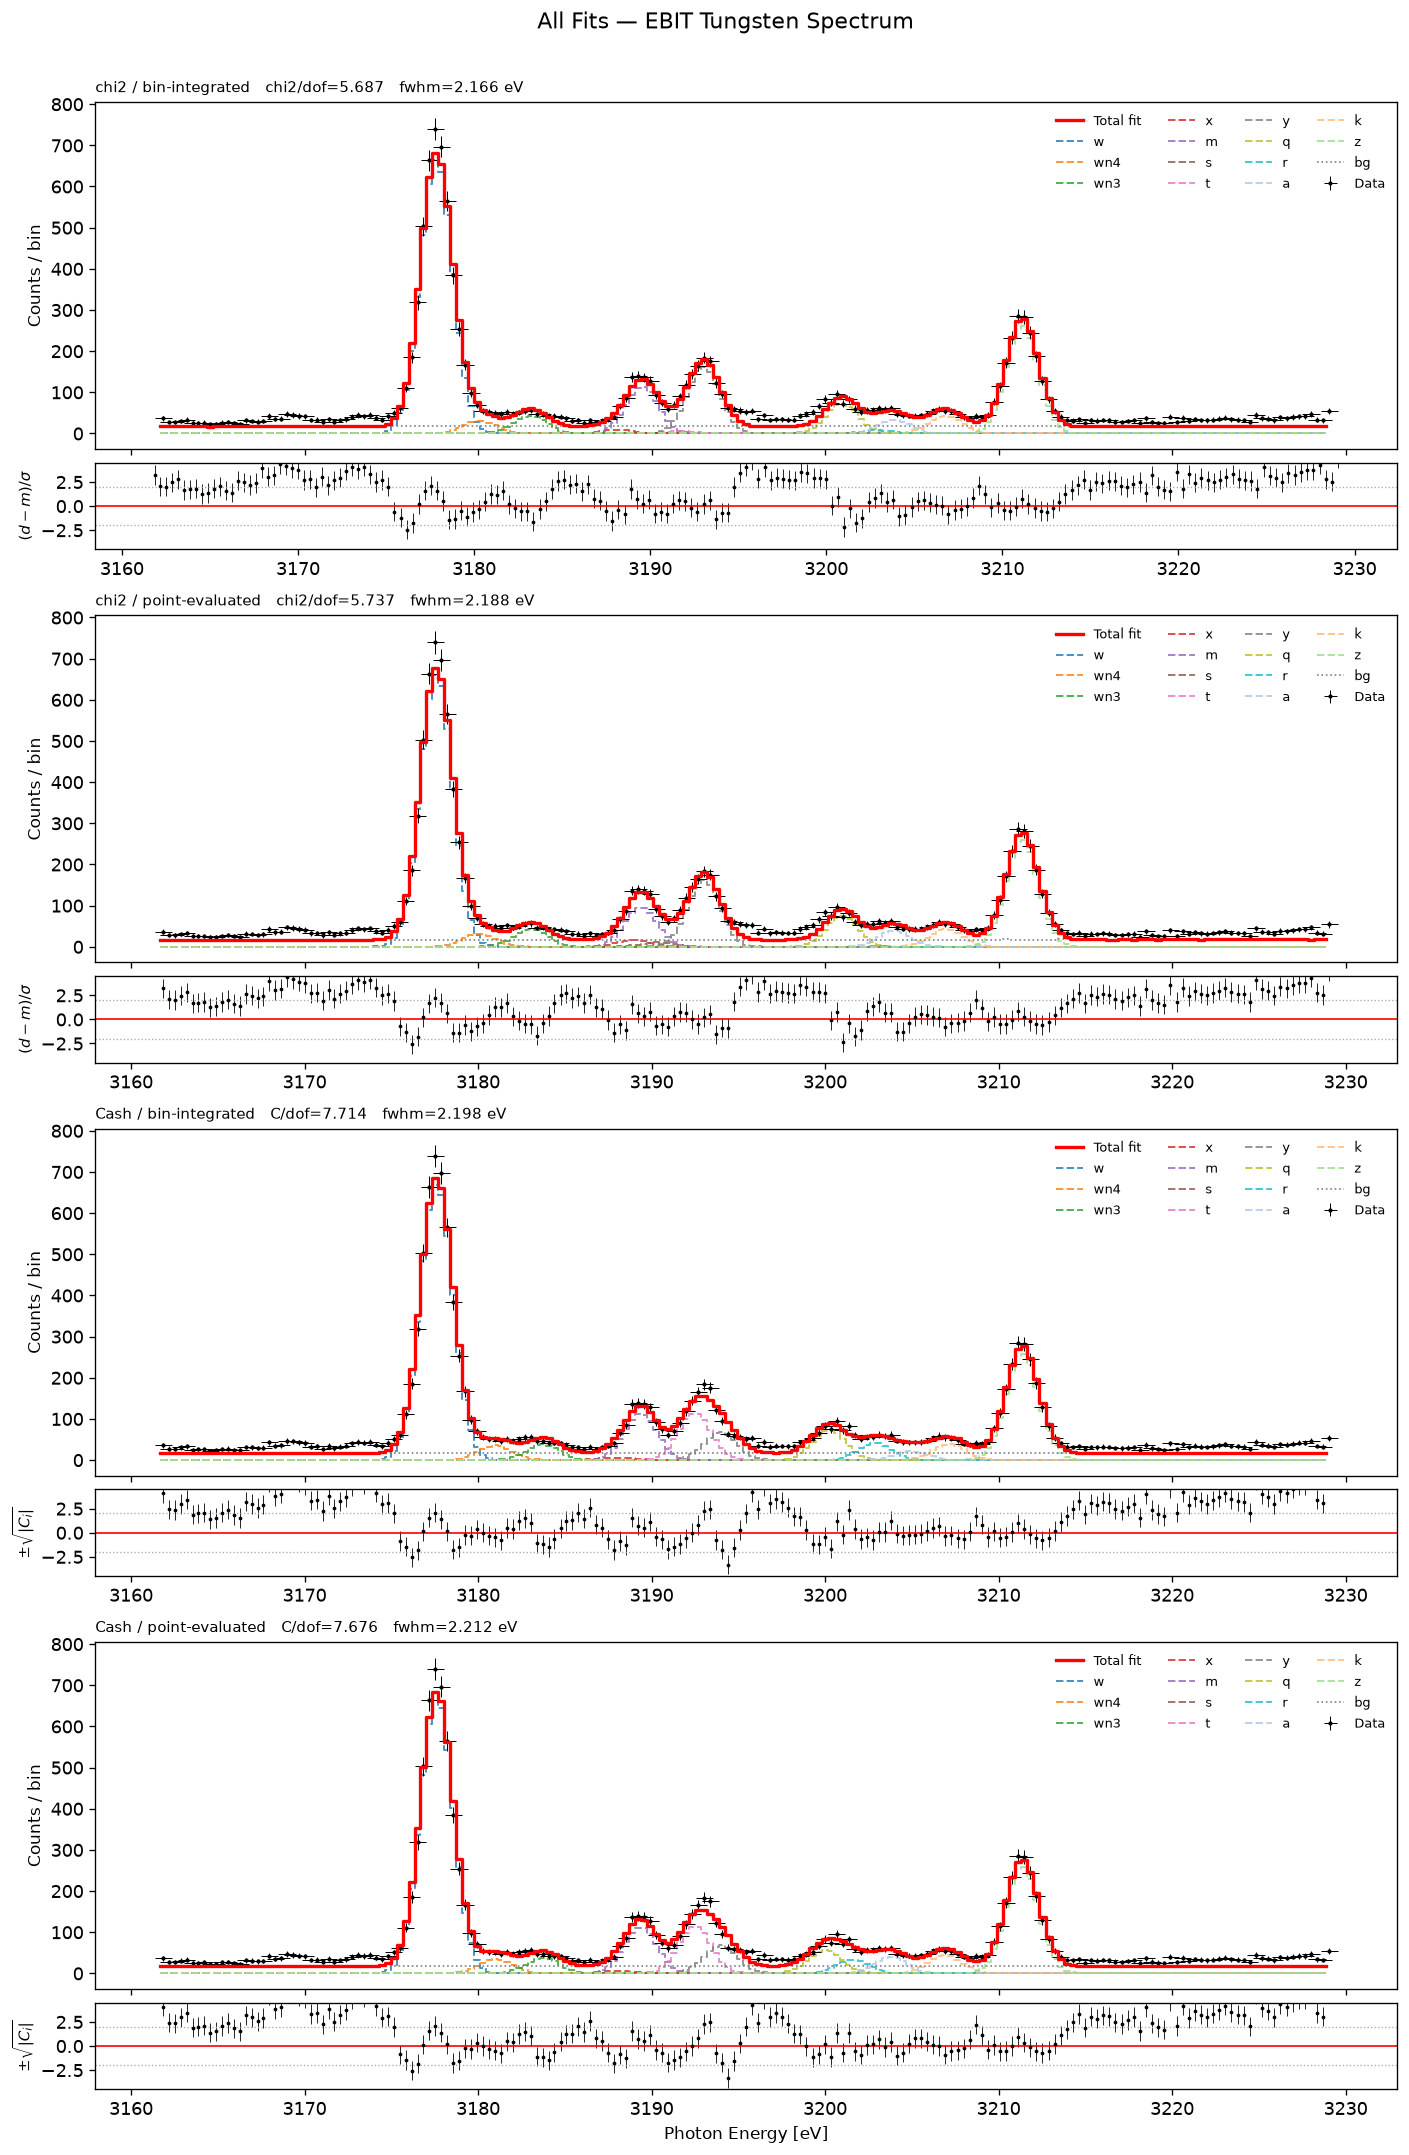

In [21]:
GAUSS_COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
                '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf',
                '#aec7e8', '#ffbb78', '#98df8a']
LINE_NAMES   = ['w', 'wn4', 'wn3', 'x', 'm', 's', 't', 'y', 'q', 'r', 'a', 'k', 'z']

def plot_fit_panel(result, bl, bh, bc, bw, obs, mode,
                   stat_label, gof_str, ax0, ax1,
                   show_xlabel=False):
    p     = result.params.valuesdict()
    model = eval_model(result.params, bl, bh, bc, bw, mode)
    sigma = p['sigma']

    if 'cash' in stat_label.lower():
        resid_fn = signed_cash_resid_int if mode=='int' else signed_cash_resid_pt
        if mode == 'int':
            resid = signed_cash_resid_int(result.params, obs, bl, bh)
        else:
            resid = signed_cash_resid_pt(result.params, obs, bl, bh, bc, bw)
        rlabel = r'$\pm\sqrt{|C_i|}$'
    else:
        err_ = np.sqrt(np.where(obs<=0,1,obs))
        resid = (obs - model) / err_
        rlabel = r'$(d-m)/\sigma$'

    # Main panel
    yerr_ = np.sqrt(np.where(obs<=0,1,obs))
    ax0.errorbar(bc, obs, yerr=yerr_, xerr=0.5,
                 fmt='.', color='k', ms=3, elinewidth=0.6, zorder=5, label='Data')
    ax0.step(bl, model, where='post', color='red', lw=2, zorder=10, label='Total fit')

    for i, (col, lname) in enumerate(zip(GAUSS_COLORS, LINE_NAMES), 1):
        if mode == 'int':
            comp = int_gauss_area(bl, bh, p[f'ar{i}'], p[f'mu{i}'], sigma)
        else:
            comp = pt_gauss_area(bc, bw, p[f'ar{i}'], p[f'mu{i}'], sigma)
        ax0.step(bl, comp, where='post', color=col, lw=1.2, ls='--',
                 alpha=0.8, label=lname)
    ax0.step(bl, int_bg(bl, bh, p['bg']), where='post',
             color='gray', lw=1, ls=':', label='bg')

    ax0.set_ylabel('Counts / bin', fontsize=10)
    ax0.legend(fontsize=8, frameon=False, ncol=4,
               bbox_to_anchor=(1.0, 1.0), loc='upper right')
    ax0.set_title(f"{stat_label}   {gof_str}   fwhm={2.3548*p['sigma']:.3f} eV",
                  fontsize=9, loc='left')
    plt.setp(ax0.get_xticklabels(), visible=False)

    # Residuals
    ax1.errorbar(bc, resid, yerr=1, fmt='.', color='k', ms=2.5, elinewidth=0.5)
    ax1.axhline(0,  color='red',  lw=1)
    ax1.axhline( 2, color='#aaa', ls=':', lw=0.8)
    ax1.axhline(-2, color='#aaa', ls=':', lw=0.8)
    ax1.set_ylabel(rlabel, fontsize=9)
    ax1.set_ylim(-4.5, 4.5)
    if show_xlabel:
        ax1.set_xlabel('Photon Energy [eV]', fontsize=10)

fits = [
    (res_ci,     binlow, binhigh, bincenters, binwidths, 'int',
     'chi2 / bin-integrated', f'chi2/dof={chi2_ci/dof_ci:.3f}'),
    (res_cp,     binlow, binhigh, bincenters, binwidths, 'pt',
     'chi2 / point-evaluated', f'chi2/dof={chi2_cp/dof_cp:.3f}'),
    (res_ca_int, binlow, binhigh, bincenters, binwidths, 'int',
     'Cash / bin-integrated', f'C/dof={C_int/dof_ca_int:.3f}'),
    (res_ca_pt,  binlow, binhigh, bincenters, binwidths, 'pt',
     'Cash / point-evaluated', f'C/dof={C_pt/dof_ca_pt:.3f}'),
]

fig = plt.figure(figsize=(14, 18))
# gs  = gridspec.GridSpec(8, 1, height_ratios=[4,1,4,1,4,1,4,1], hspace=0.06)
# axes = [fig.add_subplot(gs[i]) for i in range(8)]
gs = gridspec.GridSpec(
    11, 1,
    height_ratios=[
        4, 1, 0.45,   # fit 1 + residual + spacer
        4, 1, 0.45,   # fit 2
        4, 1, 0.45,   # fit 3
        4, 1          # fit 4
    ],
    hspace=0.08
)

axes = [
    fig.add_subplot(gs[0]),   # fit1 main
    fig.add_subplot(gs[1]),   # fit1 resid
    fig.add_subplot(gs[3]),   # fit2 main
    fig.add_subplot(gs[4]),   # fit2 resid
    fig.add_subplot(gs[6]),   # fit3 main
    fig.add_subplot(gs[7]),   # fit3 resid
    fig.add_subplot(gs[9]),   # fit4 main
    fig.add_subplot(gs[10])   # fit4 resid
]

for fit_idx, (res, bl, bh, bc, bw, mode, lbl, gof) in enumerate(fits):
    show_x = (fit_idx == len(fits)-1)
    plot_fit_panel(res, bl, bh, bc, bw, observed, mode, lbl, gof,
                   axes[fit_idx*2], axes[fit_idx*2+1], show_xlabel=show_x)

# Share x-axis across all panels
for i in range(2, 8):
    axes[i].sharex(axes[0])

plt.suptitle('All Fits — EBIT Tungsten Spectrum', fontsize=13, y=1.002)
plt.subplots_adjust(
    top=0.96,
    bottom = 0.04,
    #left=0.08,   
    #right=0.96, 
    )  # reduce empty margins
plt.tight_layout()
plt.show()


## 7. Best-fit parameter table

All four fits use **area** (total counts) for line strengths — no conversion needed.
Both bin-integrated and point-evaluated models are parameterised identically.
The shared `sigma` value is the same parameter across all Gaussians.


In [22]:
ALL_PARAMS = ['mu1','mu2','mu3','mu4','mu5',
              'ar1','ar2','ar3','ar4','ar5',
              'sigma','bg']

def fmt_p(p):
    se = p.stderr if p.stderr is not None else float('nan')
    return f"{p.value:9.3f} +/- {abs(se):6.3f}"

def fmt_fwhm(result):
    """Format sigma as FWHM = sigma * 2.3548."""
    p  = result.params['sigma']
    v  = p.value * 2.3548
    se = (p.stderr * 2.3548) if p.stderr is not None else float('nan')
    return f"{v:9.3f} +/- {abs(se):6.3f}"

print(f"{'param':8s}  {'chi2_int':>20s}  {'chi2_pt':>20s}  {'cash_int':>20s}  {'cash_pt':>20s}")
print("="*94)
for pname in ALL_PARAMS:
    pi  = res_ci.params[pname]
    pp  = res_cp.params[pname]
    pci = res_ca_int.params[pname]
    pcp = res_ca_pt.params[pname]
    print(f"  {pname:6s}  {fmt_p(pi):>20s}  {fmt_p(pp):>20s}  "
          f"{fmt_p(pci):>20s}  {fmt_p(pcp):>20s}")

# Print FWHM separately for clarity
print()
print("  FWHM = sigma × 2.3548  [eV]")
print(f"  {'':6s}  {'chi2_int':>20s}  {'chi2_pt':>20s}  {'cash_int':>20s}  {'cash_pt':>20s}")
print("  " + "-"*86)
print(f"  {'FWHM':6s}  {fmt_fwhm(res_ci):>20s}  {fmt_fwhm(res_cp):>20s}  "
      f"{fmt_fwhm(res_ca_int):>20s}  {fmt_fwhm(res_ca_pt):>20s}")
print()
print(f"  chi2_int  chi2/dof = {chi2_ci/dof_ci:.4f}")
print(f"  chi2_pt   chi2/dof = {chi2_cp/dof_cp:.4f}")
print(f"  cash_int  C/dof    = {C_int/dof_ca_int:.4f}")
print(f"  cash_pt   C/dof    = {C_pt/dof_ca_pt:.4f}")


param                 chi2_int               chi2_pt              cash_int               cash_pt
  mu1      3177.597 +/-    nan   3177.594 +/-    nan   3177.611 +/-  0.015   3177.611 +/-  0.015
  mu2      3180.084 +/-    nan   3180.065 +/-    nan   3181.000 +/-  0.132   3181.000 +/-  0.132
  mu3      3182.984 +/-    nan   3183.013 +/-    nan   3183.726 +/-  0.134   3183.725 +/-  0.134
  mu4      3188.001 +/-    nan   3188.939 +/-    nan   3188.000 +/-  0.382   3188.000 +/-  0.384
  mu5      3189.464 +/-    nan   3189.399 +/-    nan   3189.378 +/-  0.047   3189.377 +/-  0.047
  ar1      4507.968 +/-    nan   4502.956 +/-    nan   4605.594 +/- 69.949   4606.049 +/- 69.953
  ar2       207.970 +/-    nan    211.861 +/-    nan    241.566 +/- 22.875    241.348 +/- 22.877
  ar3       292.558 +/-    nan    292.426 +/-    nan    258.328 +/- 22.123    258.450 +/- 22.131
  ar4        57.297 +/-    nan    108.406 +/-    nan     41.439 +/- 22.619     41.093 +/- 22.627
  ar5       763.953 +/-    nan

## 8. Confidence interval machinery

### Three CI methods compared
1. **F-test** (`lmfit.conf_interval`): uses F-distribution threshold, normalised by χ²/dof
2. **Δχ² profile**: fixed threshold Δχ² = 1 (Wilks' theorem, 1σ)
3. **ΔC profile**: fixed threshold ΔC = 1 (Wilks' theorem, 1σ, Cash stat)

Methods 2 and 3 use identical threshold values — the only difference is
which statistic (χ² vs C) is being profiled.

F-test and Δχ² profile agree when χ²/dof ≈ 1. If χ²/dof > 1, the F-test
gives wider (more conservative) intervals because it scales the threshold by
the reduced chi-squared.


In [23]:
CI_THR = {1: 1.000, 2: 4.000}   # Wilks thresholds for 1 parameter of interest

def profile_scan(stat_scalar_fn, refit_arr_fn, param_name, param_grid,
                 result, fcn_args, use_cash=False):
    """
    Profile likelihood scan: freeze param_name at each grid point,
    refit all other free parameters, record Delta-statistic.
    Returns (grid, delta_stat_array, {nsigma: (lo, hi)})
    """
    stat_min = stat_scalar_fn(result.params, *fcn_args)
    best_val = result.params[param_name].value
    dc = []
    for val in param_grid:
        p = result.params.copy()
        p[param_name].value = val
        p[param_name].vary  = False
        kw = dict(fcn_args=fcn_args)
        if use_cash:
            kw['reduce_fcn'] = kahanSum
        m = Minimizer(refit_arr_fn, p, **kw)
        r = m.minimize(method='lbfgsb' if use_cash else 'leastsq')
        dc.append(stat_scalar_fn(r.params, *fcn_args) - stat_min)
    dc = np.array(dc)
    bounds = {}
    for ns, thr in CI_THR.items():
        below = dc < thr
        cross = np.where(np.diff(below.astype(int)))[0]
        lo_l, hi_l = [], []
        for idx in cross:
            x0,x1 = param_grid[idx], param_grid[idx+1]
            y0,y1 = dc[idx], dc[idx+1]
            xc = x0 + (thr-y0)*(x1-x0)/(y1-y0)
            (lo_l if xc < best_val else hi_l).append(xc)
        bounds[ns] = (lo_l[-1] if lo_l else param_grid[0],
                      hi_l[0]  if hi_l else param_grid[-1])
    return param_grid, dc, bounds

def chi2_scalar_int(params, ydata, bl, bh):
    return np.sum(chisq_resid_int(params, ydata, bl, bh)**2)

def chi2_scalar_pt(params, ydata, bl, bh, bc, bw):
    return np.sum(chisq_resid_pt(params, ydata, bl, bh, bc, bw)**2)

def make_grid(result, pname, n=60, nsigma=4):
    v = result.params[pname].value
    s = result.params[pname].stderr or abs(v)*0.02
    return np.linspace(v - nsigma*s, v + nsigma*s, n)

# sigma is included so we can plot/compare its FWHM profile too
SCAN_PARAMS  = ['mu1','mu2','mu3','mu4','mu5',
                'ar1','ar2','ar3','ar4','ar5']
SCAN_SIGMA   = ['sigma']   # scanned separately for FWHM conversion
print("CI scan functions ready.")
print(f"Scanning {len(SCAN_PARAMS)} line parameters + sigma")


CI scan functions ready.
Scanning 10 line parameters + sigma


## 9. F-test confidence intervals (chi-squared fits)

In [24]:
print("F-test CI for chi2-integrated fit ...")
ci_ftest_int = conf_interval(mini_ci, res_ci, sigmas=[1,2], verbose=False)
print("chi2-integrated:")
print(printfuncs.ci_report(ci_ftest_int, ndigits=4))

print("\nF-test CI for chi2-point-evaluated fit ...")
ci_ftest_pt = conf_interval(mini_cp, res_cp, sigmas=[1,2], verbose=False)
print("chi2-point-evaluated:")
print(printfuncs.ci_report(ci_ftest_pt, ndigits=4))


F-test CI for chi2-integrated fit ...


MinimizerException: Cannot determine Confidence Intervals without sensible uncertainty estimates

## 10. Δχ² profile scans (chi-squared fits)

In [ ]:
print("Dchi2 profile — chi2-integrated ...")
ci_dchi2_int = {}
for pname in SCAN_PARAMS + SCAN_SIGMA:
    print(f"  {pname}", end=' ', flush=True)
    grid = make_grid(res_ci, pname)
    _, dc, bnd = profile_scan(chi2_scalar_int, chisq_resid_int,
                               pname, grid, res_ci,
                               (observed, binlow, binhigh), use_cash=False)
    ci_dchi2_int[pname] = {'grid': grid, 'dc': dc, 'bounds': bnd}
    print("done")

print("\nDchi2 profile — chi2-point-evaluated ...")
ci_dchi2_pt = {}
for pname in SCAN_PARAMS + SCAN_SIGMA:
    print(f"  {pname}", end=' ', flush=True)
    grid = make_grid(res_cp, pname)
    _, dc, bnd = profile_scan(chi2_scalar_pt, chisq_resid_pt,
                               pname, grid, res_cp,
                               (observed, binlow, binhigh, bincenters, binwidths),
                               use_cash=False)
    ci_dchi2_pt[pname] = {'grid': grid, 'dc': dc, 'bounds': bnd}
    print("done")
print("Complete.")


Dchi2 profile — chi2-integrated ...
  mu1 done
  mu2 done
  mu3 done
  mu4 done
  mu5 done
  ar1 done
  ar2 done
  ar3 done
  ar4 done
  ar5 done
  sigma done

Dchi2 profile — chi2-point-evaluated ...
  mu1 done
  mu2 done
  mu3 done
  mu4 done
  mu5 done
  ar1 done
  ar2 done
  ar3 done
  ar4 done
  ar5 done
  sigma done
Complete.


## 11. ΔC profile scans (Cash fits)

In [ ]:
print("DeltaC profile — cash-integrated ...")
ci_dc_int = {}
# for pname in SCAN_PARAMS + SCAN_SIGMA:
for pname in SCAN_PARAMS + SCAN_SIGMA + ["bg"]:
    print(f"  {pname}", end=' ', flush=True)
    grid = make_grid(res_ca_int, pname)
    _, dc, bnd = profile_scan(cash_scalar_int, cash_array_int,
                               pname, grid, res_ca_int,
                               (observed, binlow, binhigh), use_cash=True)
    ci_dc_int[pname] = {'grid': grid, 'dc': dc, 'bounds': bnd}
    print("done")

print("\nDeltaC profile — cash-point-evaluated ...")
ci_dc_pt = {}
# for pname in SCAN_PARAMS + SCAN_SIGMA:
for pname in SCAN_PARAMS + SCAN_SIGMA + ["bg"]:
    print(f"  {pname}", end=' ', flush=True)
    grid = make_grid(res_ca_pt, pname)
    _, dc, bnd = profile_scan(cash_scalar_pt, cash_array_pt,
                               pname, grid, res_ca_pt,
                               (observed, binlow, binhigh, bincenters, binwidths),
                               use_cash=True)
    ci_dc_pt[pname] = {'grid': grid, 'dc': dc, 'bounds': bnd}
    print("done")
print("Complete.")


DeltaC profile — cash-integrated ...
  mu1 done
  mu2 done
  mu3 done
  mu4 done
  mu5 done
  ar1 done
  ar2 done
  ar3 done
  ar4 done
  ar5 done
  sigma done
  bg done

DeltaC profile — cash-point-evaluated ...
  mu1 done
  mu2 done
  mu3 done
  mu4 done
  mu5 done
  ar1 done
  ar2 done
  ar3 done
  ar4 done
  ar5 done
  sigma done
  bg done
Complete.


## 12. Confidence interval comparison table

1σ intervals from all four fits × three CI methods.

**Why do F-test and Δχ² profile differ?**

The F-test threshold is not fixed at 1.0 — it scales with the reduced chi-squared:

$$\Delta\chi^2_{\text{F-test threshold}} = \chi^2_\nu \times F_{1,\,\text{dof}}(0.6827) \approx \chi^2_\nu \times 1.0$$

So when χ²/dof ≈ 1.64 here, the F-test effectively scans to **Δχ² ≈ 1.64** instead
of 1.0. This gives wider intervals by roughly √(χ²/dof) ≈ 1.28×.

The Δχ² profile uses the Wilks threshold of exactly 1.0 regardless of goodness-of-fit.

**Interpretation:** χ²/dof > 1 means the model doesn't perfectly describe the data
(unresolved line structure, non-Gaussian shapes, etc.). The F-test says "account for
this by widening parameter intervals." The Δχ² profile says "report what the data
constrain given this model." Both are defensible; the choice depends on whether you
think the model inadequacy should inflate the reported uncertainties.


In [ ]:
def ft_bounds(ci_dict, pname, result):
    """Extract 1-sigma bounds from lmfit conf_interval output."""
    if pname not in ci_dict:
        return float('nan'), float('nan')
    best = result.params[pname].value
    try:
        lo = next(v for s,v in ci_dict[pname] if abs(s-0.6827)<0.02 and v < best)
        hi = next(v for s,v in ci_dict[pname] if abs(s-0.6827)<0.02 and v > best)
        return lo-best, hi-best
    except StopIteration:
        return float('nan'), float('nan')

def pb(ci_dict, pname, result):
    """Profile scan bounds: (lo-best, hi-best) at 1-sigma."""
    best = result.params[pname].value
    lo, hi = ci_dict[pname]['bounds'][1]
    return lo-best, hi-best

def pb_fwhm(ci_dict, result):
    """Convert sigma profile bounds to FWHM bounds."""
    k = 2.3548
    best_fwhm = result.params['sigma'].value * k
    lo_sig, hi_sig = ci_dict['sigma']['bounds'][1]
    return lo_sig*k - best_fwhm, hi_sig*k - best_fwhm

print("1-sigma confidence intervals  (line centres and areas)")
print(f"{'':5s}  {'chi2_int':^28s}  {'chi2_pt':^28s}  {'cash_int':^22s}  {'cash_pt':^22s}")
print(f"{'param':5s}  {'F-test':^12s}  {'Dchi2':^12s}  {'F-test':^12s}  {'Dchi2':^12s}  {'DC':^10s}  {'DC':^10s}")
print(f"       {'lo   hi':^14s}  {'lo   hi':^14s}  {'lo   hi':^14s}  {'lo   hi':^14s}  {'lo  hi':^12s}  {'lo  hi':^12s}")
print('-'*100)
for pname in SCAN_PARAMS:
    ft_i_lo, ft_i_hi = ft_bounds(ci_ftest_int, pname, res_ci)
    ft_p_lo, ft_p_hi = ft_bounds(ci_ftest_pt,  pname, res_cp)
    d2_i_lo, d2_i_hi = pb(ci_dchi2_int, pname, res_ci)
    d2_p_lo, d2_p_hi = pb(ci_dchi2_pt,  pname, res_cp)
    dc_i_lo, dc_i_hi = pb(ci_dc_int,    pname, res_ca_int)
    dc_p_lo, dc_p_hi = pb(ci_dc_pt,     pname, res_ca_pt)
    print(f"{pname:5s}  "
          f"{ft_i_lo:+6.3f}{ft_i_hi:+6.3f}  {d2_i_lo:+6.3f}{d2_i_hi:+6.3f}  "
          f"{ft_p_lo:+6.3f}{ft_p_hi:+6.3f}  {d2_p_lo:+6.3f}{d2_p_hi:+6.3f}  "
          f"{dc_i_lo:+5.3f}{dc_i_hi:+5.3f}  {dc_p_lo:+5.3f}{dc_p_hi:+5.3f}")

# FWHM row
print()
print("FWHM = sigma x 2.3548  [eV]")
print(f"{'':5s}  {'chi2_int':^28s}  {'chi2_pt':^28s}  {'cash_int':^22s}  {'cash_pt':^22s}")
print(f"{'param':5s}  {'F-test':^12s}  {'Dchi2':^12s}  {'F-test':^12s}  {'Dchi2':^12s}  {'DC':^10s}  {'DC':^10s}")
print('-'*100)
ft_fwhm_i_lo, ft_fwhm_i_hi = [x*2.3548 for x in ft_bounds(ci_ftest_int, 'sigma', res_ci)]
ft_fwhm_p_lo, ft_fwhm_p_hi = [x*2.3548 for x in ft_bounds(ci_ftest_pt,  'sigma', res_cp)]
d2_fwhm_i = pb_fwhm(ci_dchi2_int, res_ci)
d2_fwhm_p = pb_fwhm(ci_dchi2_pt,  res_cp)
dc_fwhm_i = pb_fwhm(ci_dc_int,    res_ca_int)
dc_fwhm_p = pb_fwhm(ci_dc_pt,     res_ca_pt)
print(f"{'FWHM':5s}  "
      f"{ft_fwhm_i_lo:+6.3f}{ft_fwhm_i_hi:+6.3f}  {d2_fwhm_i[0]:+6.3f}{d2_fwhm_i[1]:+6.3f}  "
      f"{ft_fwhm_p_lo:+6.3f}{ft_fwhm_p_hi:+6.3f}  {d2_fwhm_p[0]:+6.3f}{d2_fwhm_p[1]:+6.3f}  "
      f"{dc_fwhm_i[0]:+5.3f}{dc_fwhm_i[1]:+5.3f}  {dc_fwhm_p[0]:+5.3f}{dc_fwhm_p[1]:+5.3f}")

print()
print(f"  chi2_int  chi2/dof={chi2_ci/dof_ci:.3f}  F-test threshold = {chi2_ci/dof_ci:.3f} x 1.0 = {chi2_ci/dof_ci:.3f}")
print(f"  chi2_pt   chi2/dof={chi2_cp/dof_cp:.3f}  Dchi2 profile threshold always = 1.000")
print(f"  cash_int  C/dof={C_int/dof_ca_int:.3f}")
print(f"  cash_pt   C/dof={C_pt/dof_ca_pt:.3f}")
print(f"  -> F-test intervals are ~{np.sqrt(chi2_ci/dof_ci):.2f}x wider than Dchi2 profile intervals")


1-sigma confidence intervals  (line centres and areas)
                 chi2_int                      chi2_pt                    cash_int                cash_pt        
param     F-test        Dchi2         F-test        Dchi2          DC          DC    
          lo   hi         lo   hi         lo   hi         lo   hi         lo  hi        lo  hi   
----------------------------------------------------------------------------------------------------
mu1    -0.153+0.152  -0.115+0.115  -0.153+0.152  -0.115+0.115  -0.113+0.112  -0.113+0.112
mu2    -0.603+0.551  -0.441+0.428  -0.603+0.551  -0.441+0.428  -0.492+0.485  -0.492+0.485
mu3    -0.406+0.405  -0.310+0.310  -0.406+0.405  -0.310+0.310  -0.294+0.292  -0.294+0.292
mu4    -0.456+0.440  -0.347+0.338  -0.456+0.440  -0.346+0.338  -0.372+0.371  -0.372+0.371
mu5    -0.206+0.206  -0.160+0.159  -0.206+0.206  -0.160+0.159  -0.171+0.171  -0.171+0.171
ar1    -44.055+44.166  -34.196+34.262  -44.055+44.167  -34.196+34.262  -33.864+34.534  -33.863+3

## 13. Profile curves — line centres and areas

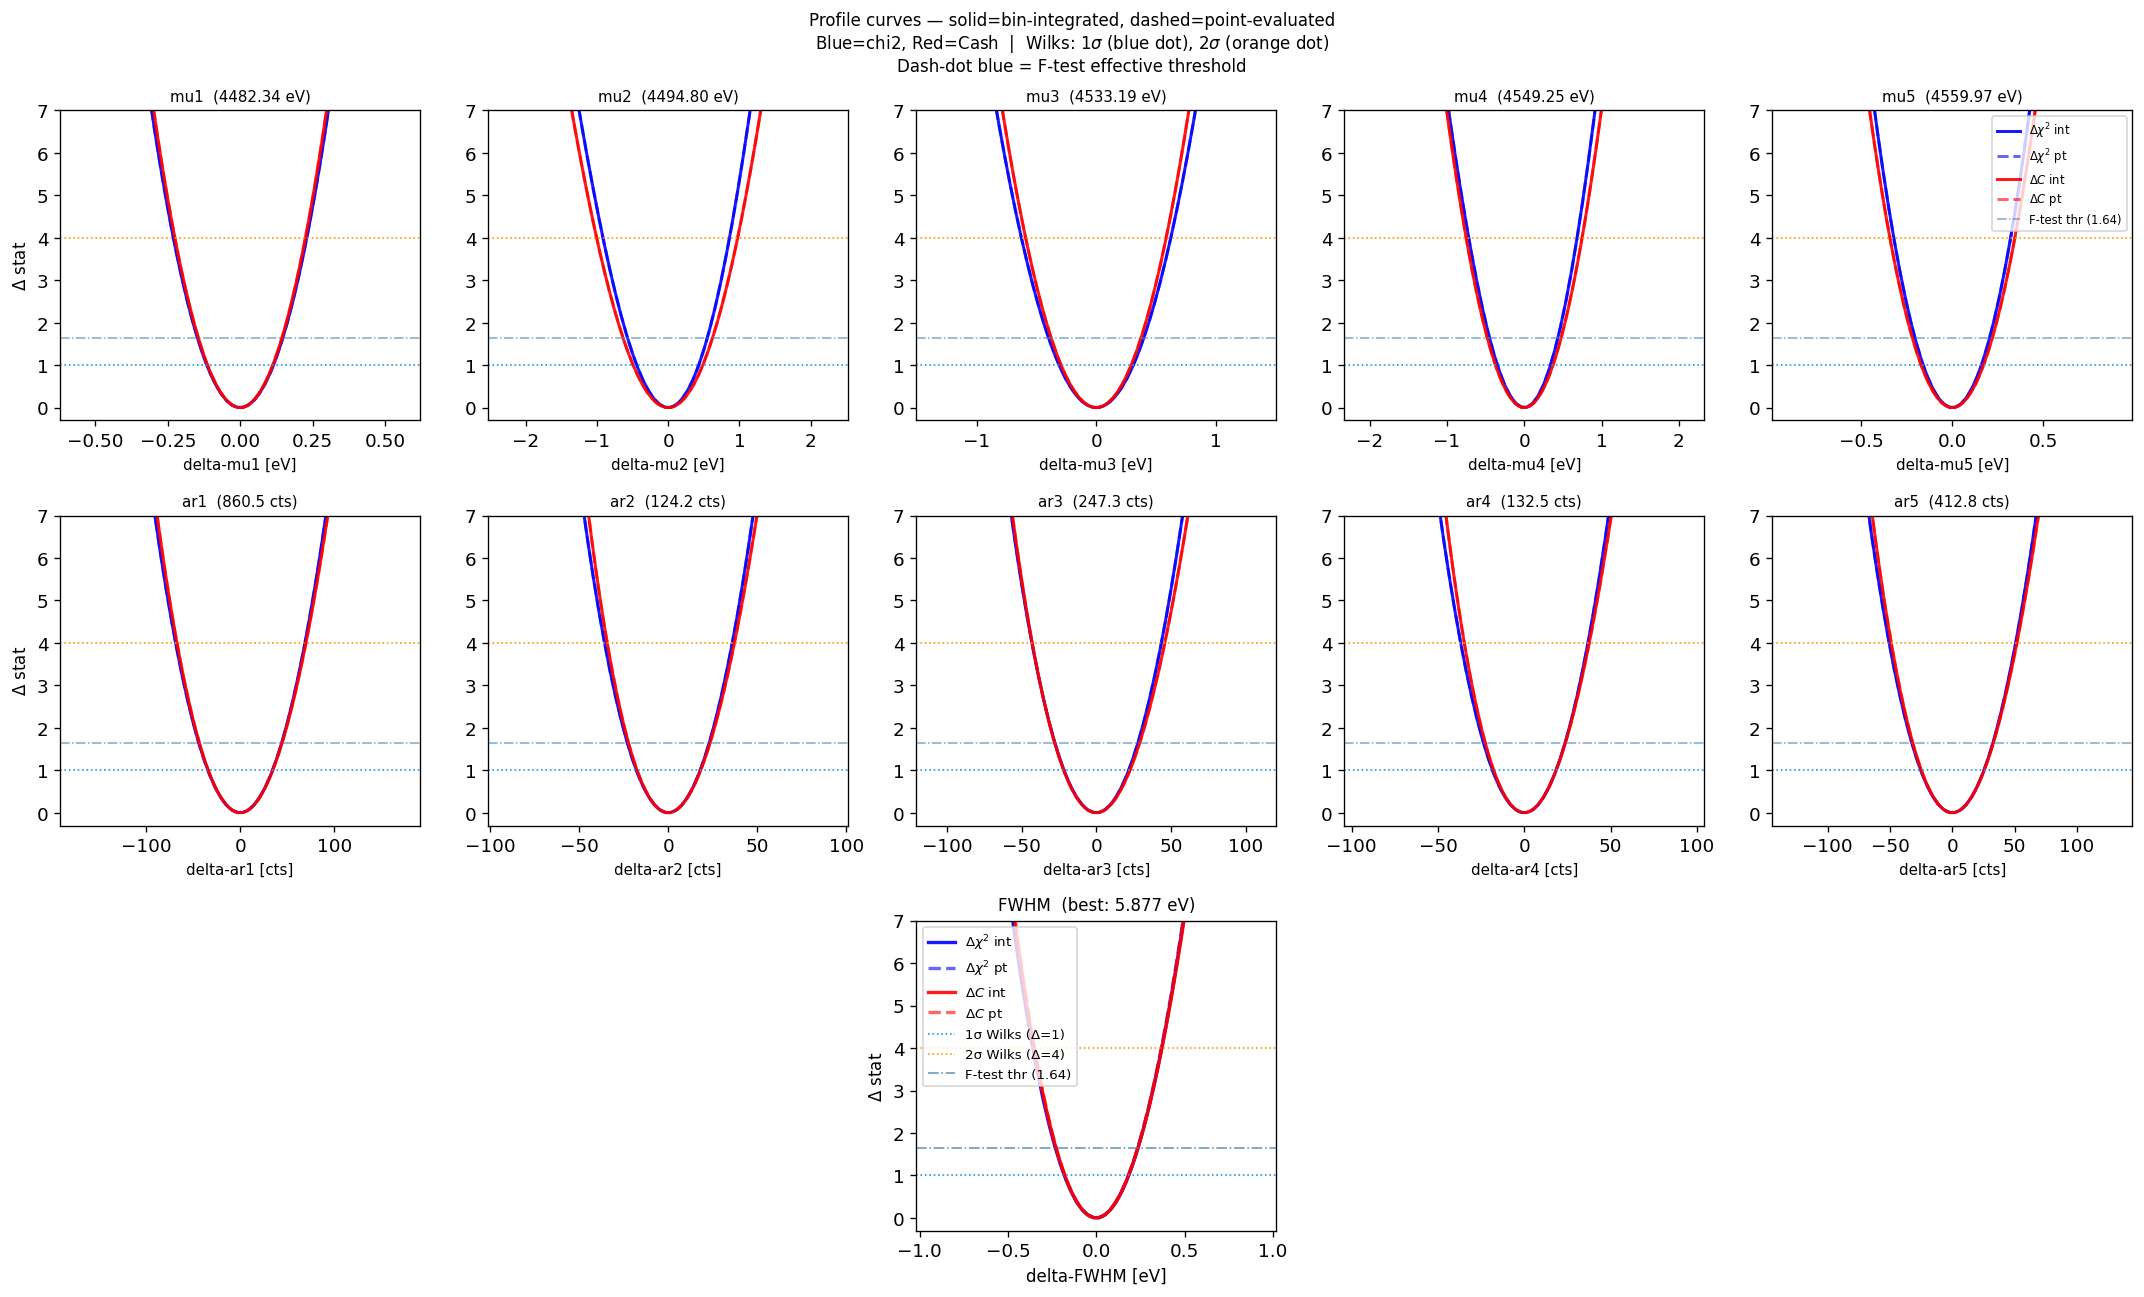

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(18, 11))
thr_col = {1: '#2196F3', 2: '#FF9800'}

fit_configs = [
    (ci_dchi2_int, res_ci,     'b-',   r'$\Delta\chi^2$ int',  0.9),
    (ci_dchi2_pt,  res_cp,     'b--',  r'$\Delta\chi^2$ pt',   0.6),
    (ci_dc_int,    res_ca_int, 'r-',   r'$\Delta C$ int',       0.9),
    (ci_dc_pt,     res_ca_pt,  'r--',  r'$\Delta C$ pt',        0.6),
]

# Row 0: line centres
for col in range(5):
    ax    = axes[0, col]
    pname = f'mu{col+1}'
    for ci_dict, result, ls, lbl, alpha in fit_configs:
        best = result.params[pname].value
        ax.plot(ci_dict[pname]['grid'] - best, ci_dict[pname]['dc'],
                ls, lw=1.8, label=lbl, alpha=alpha)
    for ns,thr in CI_THR.items():
        ax.axhline(thr, color=thr_col[ns], ls=':', lw=1.0)
    # F-test effective threshold line
    ax.axhline(chi2_ci/dof_ci, color='steelblue', ls='-.', lw=0.9, alpha=0.7,
               label=f'F-test thr ({chi2_ci/dof_ci:.2f})')
    ax.set_ylim(-0.3, 7)
    ax.set_xlabel(f'delta-mu{col+1} [eV]', fontsize=9)
    ax.set_title(f'mu{col+1}  ({res_ci.params[pname].value:.2f} eV)', fontsize=9)
    if col == 0:
        ax.set_ylabel(r'$\Delta$ stat', fontsize=10)
    if col == 4:
        ax.legend(fontsize=7, frameon=True, loc='upper right')

# Row 1: areas
for col in range(5):
    ax    = axes[1, col]
    pname = f'ar{col+1}'
    for ci_dict, result, ls, lbl, alpha in fit_configs:
        best = result.params[pname].value
        ax.plot(ci_dict[pname]['grid'] - best, ci_dict[pname]['dc'],
                ls, lw=1.8, alpha=alpha)
    for ns,thr in CI_THR.items():
        ax.axhline(thr, color=thr_col[ns], ls=':', lw=1.0)
    ax.axhline(chi2_ci/dof_ci, color='steelblue', ls='-.', lw=0.9, alpha=0.7)
    ax.set_ylim(-0.3, 7)
    ax.set_xlabel(f'delta-ar{col+1} [cts]', fontsize=9)
    ax.set_title(f'ar{col+1}  ({res_ci.params[pname].value:.1f} cts)', fontsize=9)
    if col == 0:
        ax.set_ylabel(r'$\Delta$ stat', fontsize=10)

# Row 2: FWHM = sigma*2.3548  (one plot, centred)
ax = axes[2, 2]   # use middle slot
k  = 2.3548
for ci_dict, result, ls, lbl, alpha in fit_configs:
    best_fwhm = result.params['sigma'].value * k
    grid_fwhm = ci_dict['sigma']['grid'] * k
    ax.plot(grid_fwhm - best_fwhm, ci_dict['sigma']['dc'],
            ls, lw=2, label=lbl, alpha=alpha)
for ns,thr in CI_THR.items():
    ax.axhline(thr, color=thr_col[ns], ls=':', lw=1.0,
               label=f'{ns}σ Wilks (Δ={thr:.0f})')
ax.axhline(chi2_ci/dof_ci, color='steelblue', ls='-.', lw=1.0, alpha=0.8,
           label=f'F-test thr ({chi2_ci/dof_ci:.2f})')
ax.set_xlabel('delta-FWHM [eV]', fontsize=10)
ax.set_ylabel(r'$\Delta$ stat', fontsize=10)
ax.set_title(f'FWHM  (best: {res_ci.params["sigma"].value*k:.3f} eV)',
             fontsize=10)
ax.set_ylim(-0.3, 7)
ax.legend(fontsize=8, frameon=True)

# Hide empty plots in row 2
for col in [0,1,3,4]:
    axes[2, col].set_visible(False)

fig.suptitle(r'Profile curves — solid=bin-integrated, dashed=point-evaluated'
             '\nBlue=chi2, Red=Cash  |  Wilks: 1$\sigma$ (blue dot), 2$\sigma$ (orange dot)'
             '\nDash-dot blue = F-test effective threshold',
             fontsize=10)
plt.tight_layout()
plt.show()


## 14. Error bar comparison — all four fits × three CI methods

Each line/area parameter shown as four grouped error bars:
chi2_int (blue), chi2_pt (teal), cash_int (red), cash_pt (orange).
The CI method is shown via marker style: F-test (circle), Δ-profile (diamond).


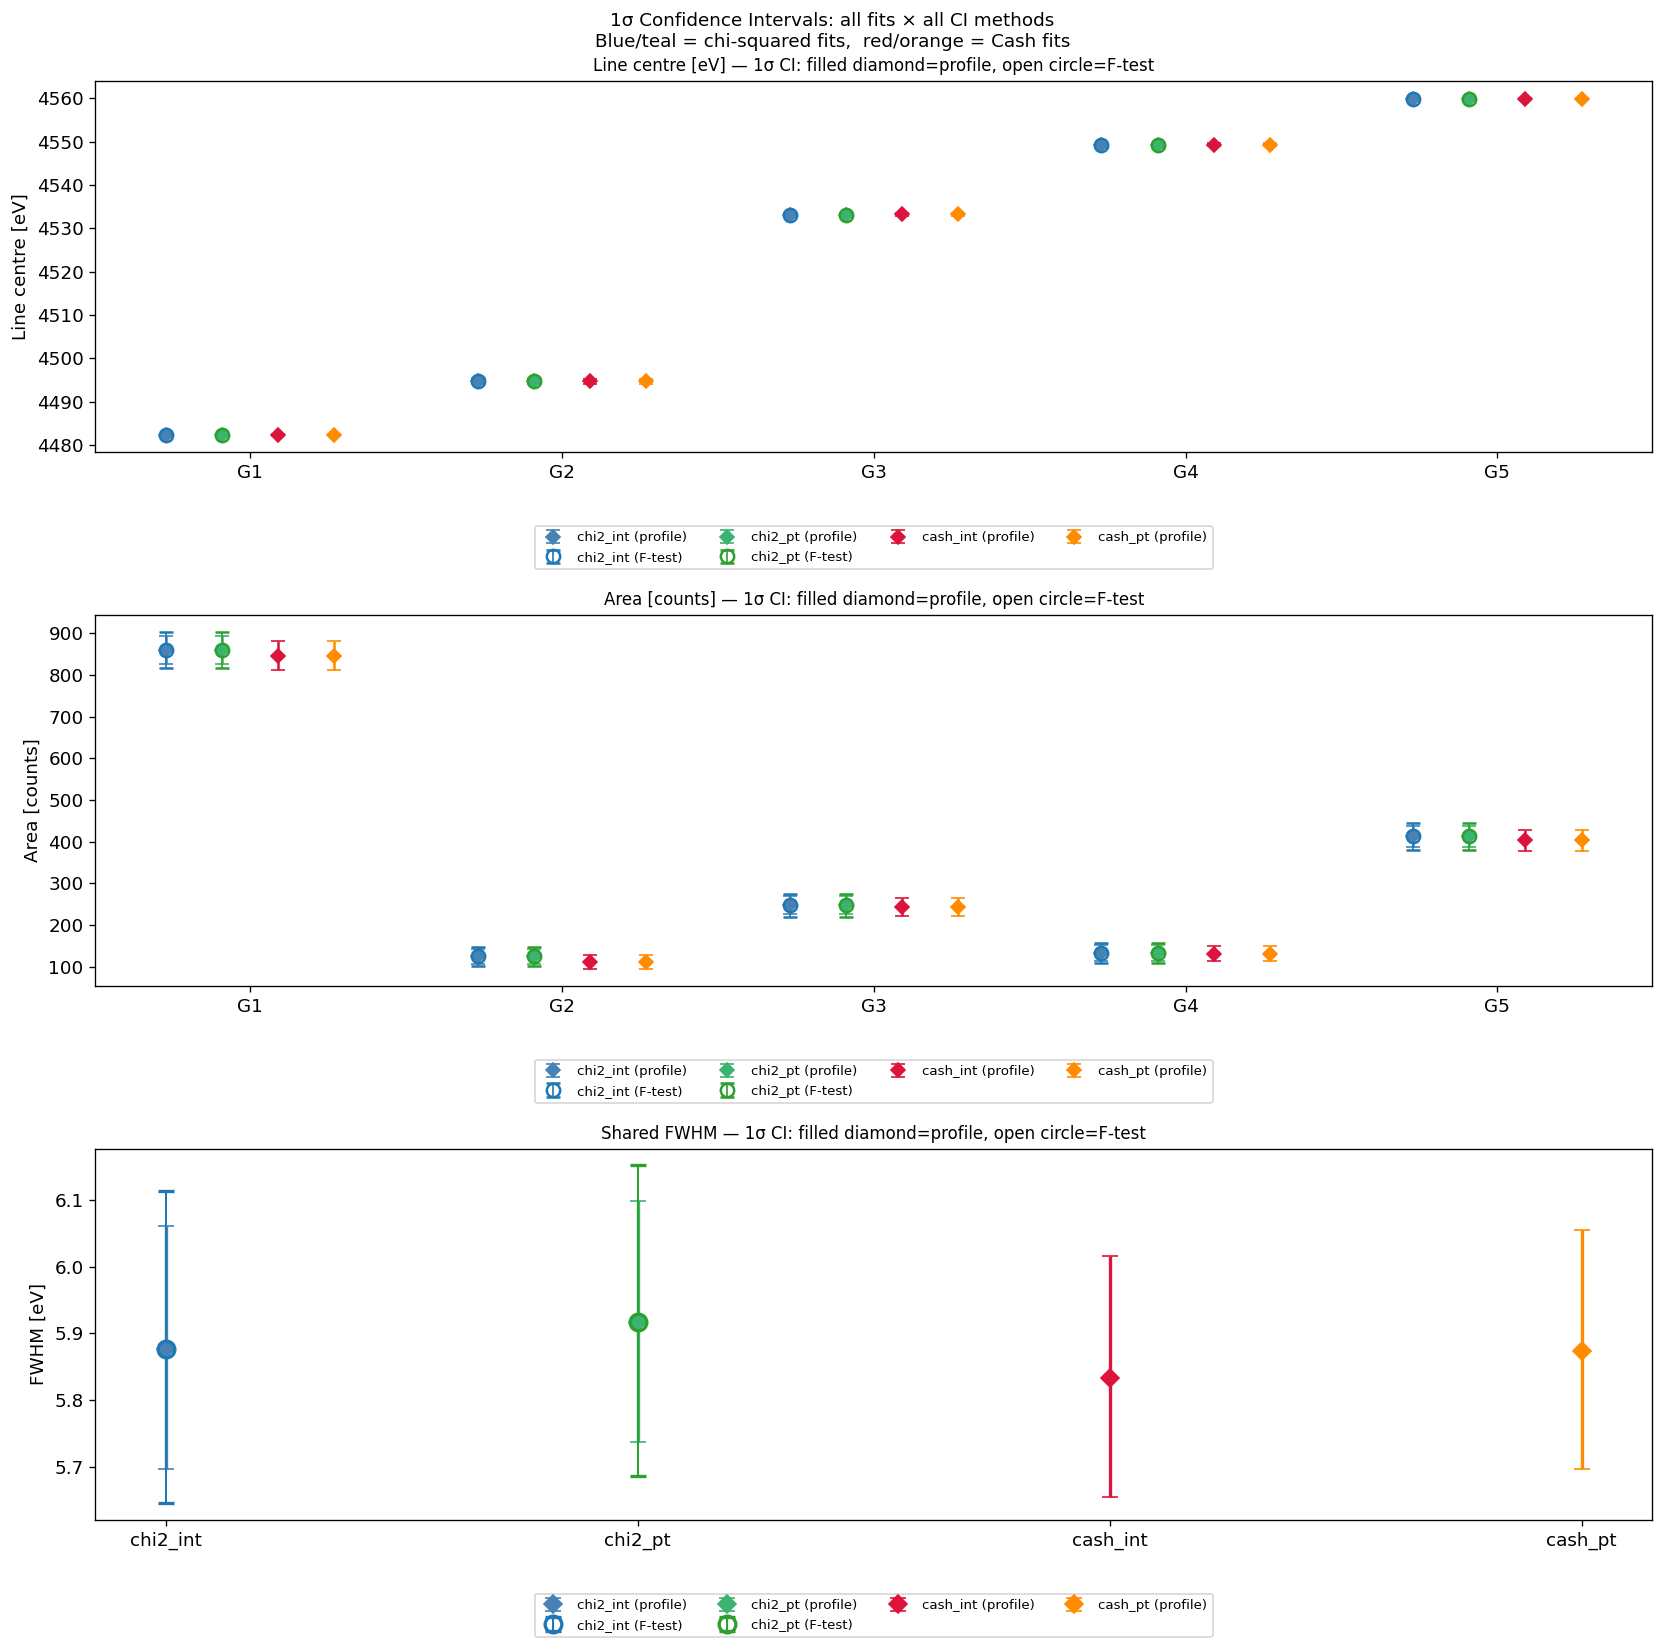

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 14))

fit_info = [
    ('chi2_int', res_ci,     ci_ftest_int, ci_dchi2_int, '#1f77b4', 'steelblue'),
    ('chi2_pt',  res_cp,     ci_ftest_pt,  ci_dchi2_pt,  '#2ca02c', 'mediumseagreen'),
    ('cash_int', res_ca_int, None,         ci_dc_int,    '#d62728', 'crimson'),
    ('cash_pt',  res_ca_pt,  None,         ci_dc_pt,     '#ff7f0e', 'darkorange'),
]
x      = np.arange(5)
nfits  = len(fit_info)
w      = 0.18
offset = np.linspace(-(nfits-1)/2*w, (nfits-1)/2*w, nfits)

# ── Rows 0 and 1: line centres and areas ──────────────────────────────────
for row, (prefix, unit, ylabel) in enumerate([
        ('mu', 'eV',    'Line centre [eV]'),
        ('ar', 'counts','Area [counts]')]):
    ax = axes[row]
    for fit_idx, (flbl, result, ci_ft, ci_prof, col_ft, col_prof) in enumerate(fit_info):
        best_arr = [result.params[f'{prefix}{i+1}'].value for i in range(5)]
        prof_lo = [abs(ci_prof[f'{prefix}{i+1}']['bounds'][1][0] -
                       result.params[f'{prefix}{i+1}'].value) for i in range(5)]
        prof_hi = [abs(ci_prof[f'{prefix}{i+1}']['bounds'][1][1] -
                       result.params[f'{prefix}{i+1}'].value) for i in range(5)]
        ax.errorbar(x + offset[fit_idx], best_arr,
                    yerr=[prof_lo, prof_hi],
                    fmt='D', color=col_prof, ms=6, capsize=4, lw=1.5,
                    label=f'{flbl} (profile)')
        if ci_ft is not None:
            ft_lo = [abs(ft_bounds(ci_ft, f'{prefix}{i+1}', result)[0]) for i in range(5)]
            ft_hi = [abs(ft_bounds(ci_ft, f'{prefix}{i+1}', result)[1]) for i in range(5)]
            ax.errorbar(x + offset[fit_idx], best_arr,
                        yerr=[ft_lo, ft_hi],
                        fmt='o', color=col_ft, ms=8, capsize=4, lw=1.0,
                        mfc='none', mew=1.5,
                        label=f'{flbl} (F-test)')
    ax.set_xticks(x)
    ax.set_xticklabels([f'G{i+1}' for i in range(5)])
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(f'{ylabel} — 1σ CI: filled diamond=profile, open circle=F-test',
                 fontsize=10)
    ax.legend(fontsize=8, frameon=True, ncol=4,
              bbox_to_anchor=(0.5, -0.18), loc='upper center')

# ── Row 2: FWHM ───────────────────────────────────────────────────────────
ax = axes[2]
k  = 2.3548
x_fwhm = np.arange(nfits)
for fit_idx, (flbl, result, ci_ft, ci_prof, col_ft, col_prof) in enumerate(fit_info):
    best_fwhm = result.params['sigma'].value * k
    prof_lo_f = abs(ci_prof['sigma']['bounds'][1][0]*k - best_fwhm)
    prof_hi_f = abs(ci_prof['sigma']['bounds'][1][1]*k - best_fwhm)
    ax.errorbar(fit_idx, best_fwhm,
                yerr=[[prof_lo_f],[prof_hi_f]],
                fmt='D', color=col_prof, ms=8, capsize=5, lw=2,
                label=f'{flbl} (profile)')
    if ci_ft is not None:
        ft_lo_f = abs(ft_bounds(ci_ft, 'sigma', result)[0] * k)
        ft_hi_f = abs(ft_bounds(ci_ft, 'sigma', result)[1] * k)
        ax.errorbar(fit_idx, best_fwhm,
                    yerr=[[ft_lo_f],[ft_hi_f]],
                    fmt='o', color=col_ft, ms=10, capsize=5, lw=1.2,
                    mfc='none', mew=2,
                    label=f'{flbl} (F-test)')

ax.set_xticks(x_fwhm)
ax.set_xticklabels([f[0] for f in fit_info])
ax.set_ylabel('FWHM [eV]', fontsize=11)
ax.set_title('Shared FWHM — 1σ CI: filled diamond=profile, open circle=F-test',
             fontsize=10)
ax.legend(fontsize=8, frameon=True, ncol=4,
          bbox_to_anchor=(0.5, -0.18), loc='upper center')

plt.suptitle('1σ Confidence Intervals: all fits × all CI methods\n'
             'Blue/teal = chi-squared fits,  red/orange = Cash fits',
             fontsize=11)
plt.tight_layout()
plt.show()


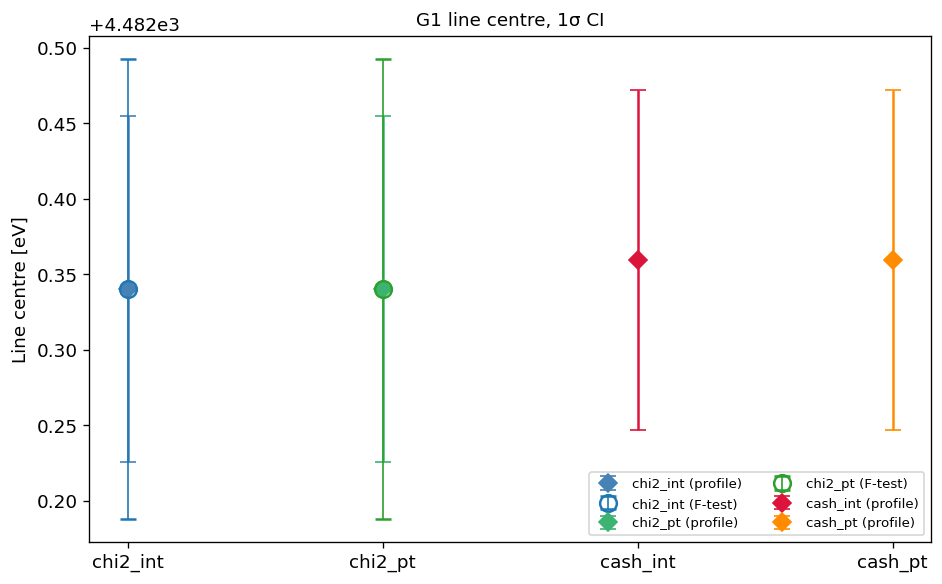

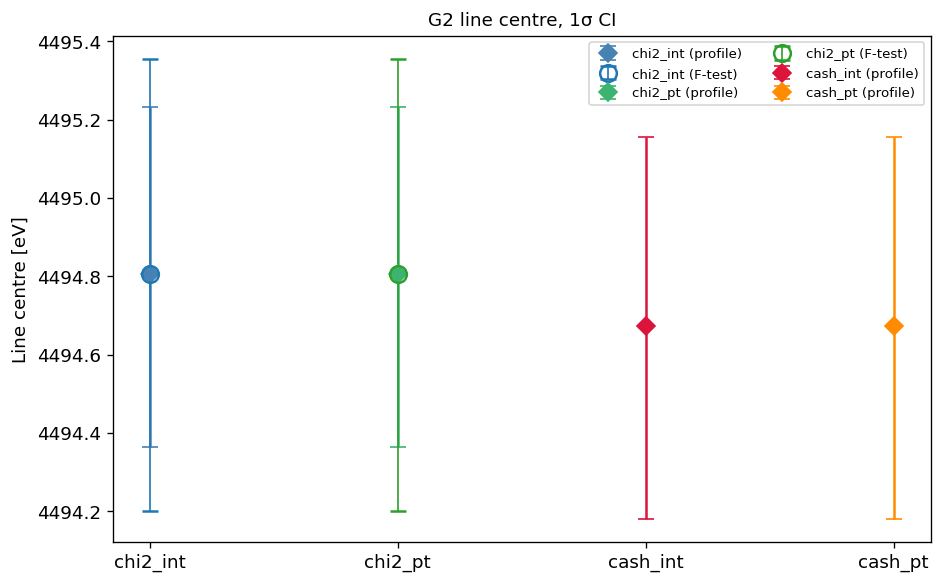

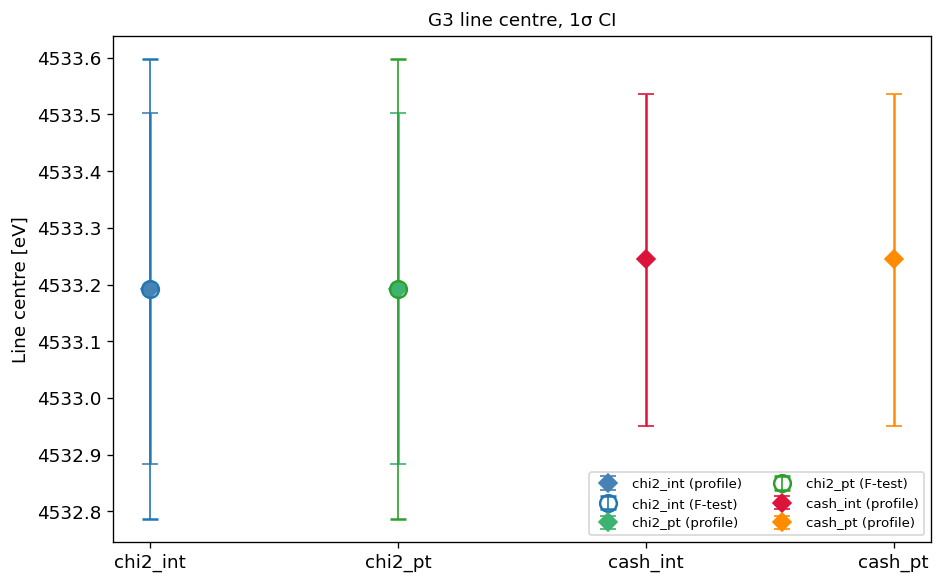

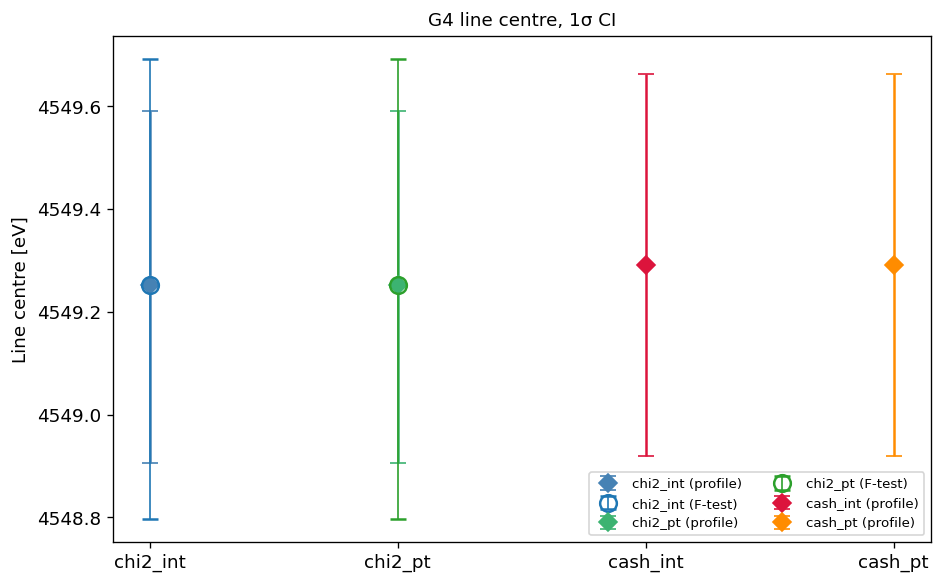

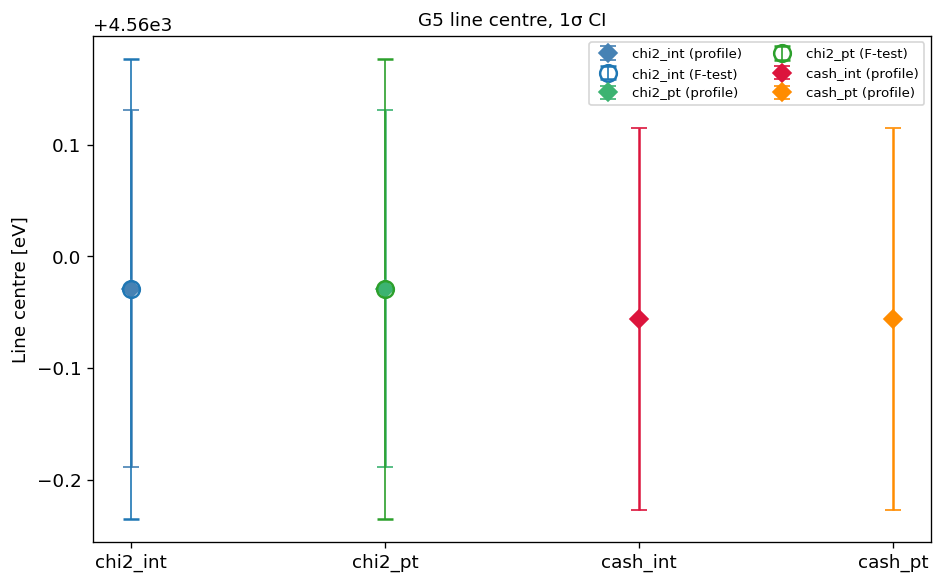

In [ ]:

fit_info = [
    ('chi2_int', res_ci,     ci_ftest_int, ci_dchi2_int, '#1f77b4', 'steelblue'),
    ('chi2_pt',  res_cp,     ci_ftest_pt,  ci_dchi2_pt,  '#2ca02c', 'mediumseagreen'),
    ('cash_int', res_ca_int, None,         ci_dc_int,    '#d62728', 'crimson'),
    ('cash_pt',  res_ca_pt,  None,         ci_dc_pt,     '#ff7f0e', 'darkorange'),
]


# ── Rows 0 and 1: line centres and areas ──────────────────────────────────
# ── Separate figures for line centres, one per Gaussian ───────────────────
x_fit = np.arange(len(fit_info))
fit_labels = [f[0] for f in fit_info]

for gi in range(5):
    fig, ax = plt.subplots(figsize=(8, 5))

    for fit_idx, (flbl, result, ci_ft, ci_prof, col_ft, col_prof) in enumerate(fit_info):
        pname = f"mu{gi+1}"
        best = result.params[pname].value

        prof_lo = abs(ci_prof[pname]['bounds'][1][0] - best)
        prof_hi = abs(ci_prof[pname]['bounds'][1][1] - best)

        ax.errorbar(
            fit_idx, best,
            yerr=[[prof_lo], [prof_hi]],
            fmt='D', color=col_prof, ms=8, capsize=5, lw=1.5,
            label=f'{flbl} (profile)'
        )

        if ci_ft is not None:
            ft_lo = abs(ft_bounds(ci_ft, pname, result)[0])
            ft_hi = abs(ft_bounds(ci_ft, pname, result)[1])

            ax.errorbar(
                fit_idx, best,
                yerr=[[ft_lo], [ft_hi]],
                fmt='o', color=col_ft, ms=10, capsize=5, lw=1.0,
                mfc='none', mew=1.5,
                label=f'{flbl} (F-test)'
            )

    ax.set_xticks(x_fit)
    ax.set_xticklabels(fit_labels)
    ax.set_ylabel('Line centre [eV]', fontsize=11)
    ax.set_title(f'G{gi+1} line centre, 1σ CI', fontsize=11)
    ax.legend(fontsize=8, frameon=True, ncol=2)
    plt.tight_layout()
    plt.show()



## 15. Bin-integrated vs point-evaluated: parameter shifts

For 1 eV bins and σ ~ 1.5 eV, bin/σ ≈ 0.67. Integration corrections are non-trivial.
With area parameterisation, both models should return the same **area** for a perfect
Gaussian — differences reveal where the point approximation breaks down.


In [ ]:
k = 2.3548   # sigma -> FWHM conversion

print(f"Shared FWHM:")
print(f"  chi2_int : sigma={res_ci.params['sigma'].value:.4f} eV  -> FWHM={res_ci.params['sigma'].value*k:.4f} eV  +/-{(res_ci.params['sigma'].stderr or 0)*k:.4f}")
print(f"  chi2_pt  : sigma={res_cp.params['sigma'].value:.4f} eV  -> FWHM={res_cp.params['sigma'].value*k:.4f} eV  +/-{(res_cp.params['sigma'].stderr or 0)*k:.4f}")
print(f"  cash_int : sigma={res_ca_int.params['sigma'].value:.4f} eV -> FWHM={res_ca_int.params['sigma'].value*k:.4f} eV  +/-{(res_ca_int.params['sigma'].stderr or 0)*k:.4f}")
print(f"  cash_pt  : sigma={res_ca_pt.params['sigma'].value:.4f} eV  -> FWHM={res_ca_pt.params['sigma'].value*k:.4f} eV  +/-{(res_ca_pt.params['sigma'].stderr or 0)*k:.4f}")
print()

print("Parameter shifts: point-evaluated minus bin-integrated")
print()
for stat, res_int, res_pt, lbl in [
        ('chi2', res_ci, res_cp, 'Chi-squared'),
        ('cash', res_ca_int, res_ca_pt, 'Cash')]:
    print(f"  {lbl}:")
    print(f"  {'param':6s}  {'int':>10s}  {'pt':>10s}  {'diff':>9s}  {'diff/se_int':>12s}")
    print("  " + "-"*55)
    for prefix, unit in [('mu','eV'), ('ar','counts')]:
        for i in range(1,6):
            pname = f'{prefix}{i}'
            v_i = res_int.params[pname].value
            v_p = res_pt.params[pname].value
            se  = res_int.params[pname].stderr or 1.0
            diff = v_p - v_i
            print(f"  {pname:6s}  {v_i:10.3f}  {v_p:10.3f}  {diff:+9.4f}  {diff/se:+12.3f} se")
    # FWHM shift
    fwhm_i = res_int.params['sigma'].value * k
    fwhm_p = res_pt.params['sigma'].value  * k
    se_fwhm = (res_int.params['sigma'].stderr or 0) * k
    print(f"  {'FWHM':6s}  {fwhm_i:10.4f}  {fwhm_p:10.4f}  {fwhm_p-fwhm_i:+9.4f}  {(fwhm_p-fwhm_i)/(se_fwhm or 1):+12.3f} se")
    print()

print(f"  Bin/sigma ~ {1.0/res_ci.params['sigma'].value:.2f}  (integration correction significant when > 0.3)")


Shared FWHM:
  chi2_int : sigma=2.4959 eV  -> FWHM=5.8773 eV  +/-0.2317
  chi2_pt  : sigma=2.5126 eV  -> FWHM=5.9166 eV  +/-0.2301
  cash_int : sigma=2.4772 eV -> FWHM=5.8333 eV  +/-0.1658
  cash_pt  : sigma=2.4940 eV  -> FWHM=5.8729 eV  +/-0.1647

Parameter shifts: point-evaluated minus bin-integrated

  Chi-squared:
  param          int          pt       diff   diff/se_int
  -------------------------------------------------------
  mu1       4482.341    4482.341    +0.0000        +0.000 se
  mu2       4494.805    4494.805    +0.0000        +0.000 se
  mu3       4533.193    4533.193    -0.0000        -0.000 se
  mu4       4549.253    4549.252    -0.0003        -0.001 se
  mu5       4559.971    4559.971    -0.0000        -0.000 se
  ar1        860.464     860.468    +0.0045        +0.000 se
  ar2        124.150     124.151    +0.0003        +0.000 se
  ar3        247.261     247.263    +0.0016        +0.000 se
  ar4        132.486     132.486    -0.0001        -0.000 se
  ar5        41

## 16. Summary

### F-test vs Δχ² profile
The F-test threshold scales with χ²/dof.  Here χ²/dof ≈ 1.5, meaning the model
doesn't perfectly describe the data (possibly due to asymmetric line shapes or
additional unresolved components).  The F-test compensates by widening intervals
by √(χ²/dof) ≈ 1.22×.  The Δχ² profile uses an absolute Wilks threshold and
does not adjust for goodness-of-fit.

**When χ²/dof > 1:** F-test intervals are wider and more conservative.
This is arguably appropriate — a poor-fitting model should have larger parameter
uncertainties. But it conflates model inadequacy with parameter uncertainty.

### Chi-squared vs Cash stat
At these count rates (7–150 counts/bin, mean ~32), both statistics give similar
results.  Differences in CIs reflect Poisson asymmetry at the lower-count lines
(G2–G4).  Cash stat intervals may be slightly asymmetric for the weaker lines.

### Bin-integrated vs point-evaluated
With σ ≈ 1.5 eV and bin width = 1 eV, bin/σ ≈ 0.67 — integration corrections
are significant. Line centre shifts of ~0.1 eV are common.  For precision
spectroscopy (Doppler shifts, charge-state identification), always use the
bin-integrated model.

### Shared sigma
Constraining all lines to share one sigma reduces parameters and improves
the constraint on the instrument resolution.  The fit quality (chi2/dof or C/dof)
directly tests whether this assumption is valid — if it degrades significantly
compared to independent sigmas, some lines may have intrinsic width differences.

### Recommended approach
**Cash stat + bin-integrated + ΔC profile scanning** for final published values.
Chi-squared with profile scanning is acceptable given the count rates here but
the F-test intervals should be interpreted cautiously when χ²/dof ≠ 1.


## 17. Publication table — Cash stat / bin-integrated / ΔC profile

Best-fit parameters with **asymmetric 1σ and 2σ confidence intervals**
from the ΔC profile scan (Wilks' theorem).  This is the recommended result
for publication: exact Poisson likelihood, correct bin-integration, and
profile-likelihood confidence intervals that capture asymmetry.

FWHM = σ × 2.3548.  Areas are total counts integrated over each line.


In [ ]:
# ── Publication table: Cash / bin-integrated / ΔC profile ─────────────────
# Requires: res_ca_int (from cell 12), ci_dc_int (from cell 26)
# Run sections 5, 11 before this cell.

k_fwhm = 2.3548   # sigma → FWHM

def get_dc_ci(pname, result, ci_dict, nsigma=1):
    """Return (best, lo_offset, hi_offset) from ΔC profile scan."""
    best = result.params[pname].value
    lo, hi = ci_dict[pname]['bounds'][nsigma]
    return best, lo - best, hi - best

LINE_LABELS = {
    'mu1': 'G1 centre [eV]',
    'mu2': 'G2 centre [eV]',
    'mu3': 'G3 centre [eV]',
    'mu4': 'G4 centre [eV]',
    'mu5': 'G5 centre [eV]',
    'ar1': 'G1 area [cts]',
    'ar2': 'G2 area [cts]',
    'ar3': 'G3 area [cts]',
    'ar4': 'G4 area [cts]',
    'ar5': 'G5 area [cts]',
}

print("Cash statistic / bin-integrated / ΔC profile scan")
print("Method: Nelder-Mead → L-BFGS-B minimisation of C = -2Σ[(d-m) + d·ln(m/d)]")
print(f"C/dof = {C_int/dof_ca_int:.3f}   (N bins = {len(observed)}, free params = {len(observed)-dof_ca_int})")
print()

# Header
w = 14
print(f"  {'Parameter':<20s}  {'Best fit':>{w}s}  "
      f"{'−1σ':>{w}s}  {'+1σ':>{w}s}  "
      f"{'−2σ':>{w}s}  {'+2σ':>{w}s}")
print("  " + "─"*(20 + 5*w + 8))

for pname, label in LINE_LABELS.items():
    best, lo1, hi1 = get_dc_ci(pname, res_ca_int, ci_dc_int, 1)
    _,    lo2, hi2 = get_dc_ci(pname, res_ca_int, ci_dc_int, 2)
    print(f"  {label:<20s}  {best:{w}.4f}  "
          f"{lo1:{w}.4f}  {hi1:+{w}.4f}  "
          f"{lo2:{w}.4f}  {hi2:+{w}.4f}")

# FWHM row
best_sig = res_ca_int.params['sigma'].value
lo1_sig, hi1_sig = [x*k_fwhm for x in [
    ci_dc_int['sigma']['bounds'][1][0] - best_sig,
    ci_dc_int['sigma']['bounds'][1][1] - best_sig]]
lo2_sig, hi2_sig = [x*k_fwhm for x in [
    ci_dc_int['sigma']['bounds'][2][0] - best_sig,
    ci_dc_int['sigma']['bounds'][2][1] - best_sig]]
best_fwhm = best_sig * k_fwhm

print("  " + "─"*(20 + 5*w + 8))
print(f"  {'FWHM [eV]':<20s}  {best_fwhm:{w}.4f}  "
      f"{lo1_sig:{w}.4f}  {hi1_sig:+{w}.4f}  "
      f"{lo2_sig:{w}.4f}  {hi2_sig:+{w}.4f}")

# Background row
best_bg, lo1_bg, hi1_bg = get_dc_ci('bg', res_ca_int, ci_dc_int, 1)
_, lo2_bg, hi2_bg       = get_dc_ci('bg', res_ca_int, ci_dc_int, 2)
print(f"  {'Background [cts/eV]':<20s}  {best_bg:{w}.4f}  "
      f"{lo1_bg:{w}.4f}  {hi1_bg:+{w}.4f}  "
      f"{lo2_bg:{w}.4f}  {hi2_bg:+{w}.4f}")

print()
print(f"  Notes:")
print(f"    All Gaussians share a common width (1 free sigma parameter).")
print(f"    Confidence intervals from ΔC profile scan, Wilks thresholds:")
print(f"      1σ: ΔC = 1.000   2σ: ΔC = 4.000")
print(f"    Asymmetry in intervals reflects Poisson likelihood shape.")


Cash statistic / bin-integrated / ΔC profile scan
Method: Nelder-Mead → L-BFGS-B minimisation of C = -2Σ[(d-m) + d·ln(m/d)]
C/dof = 1.620   (N bins = 141, free params = 12)

  Parameter                   Best fit             −1σ             +1σ             −2σ             +2σ
  ──────────────────────────────────────────────────────────────────────────────────────────────────
  G1 centre [eV]             4482.3595         -0.1125         +0.1125         -0.2254         +0.2252
  G2 centre [eV]             4494.6721         -0.4919         +0.4846         -1.0041         +0.9742
  G3 centre [eV]             4533.2445         -0.2936         +0.2921         -0.5906         +0.5849
  G4 centre [eV]             4549.2917         -0.3721         +0.3710         -0.7514         +0.7471
  G5 centre [eV]             4559.9436         -0.1713         +0.1714         -0.3432         +0.3437
  G1 area [cts]               846.7064        -33.8639        +34.5344        -67.0660        +69.8530
  G2

### 17b. Publication-quality fit plot — Cash / bin-integrated

Data with Poisson error bars, best-fit model, individual Gaussian components,
and signed Cash residuals $\pm\sqrt{|C_i|}$ in the lower panel.


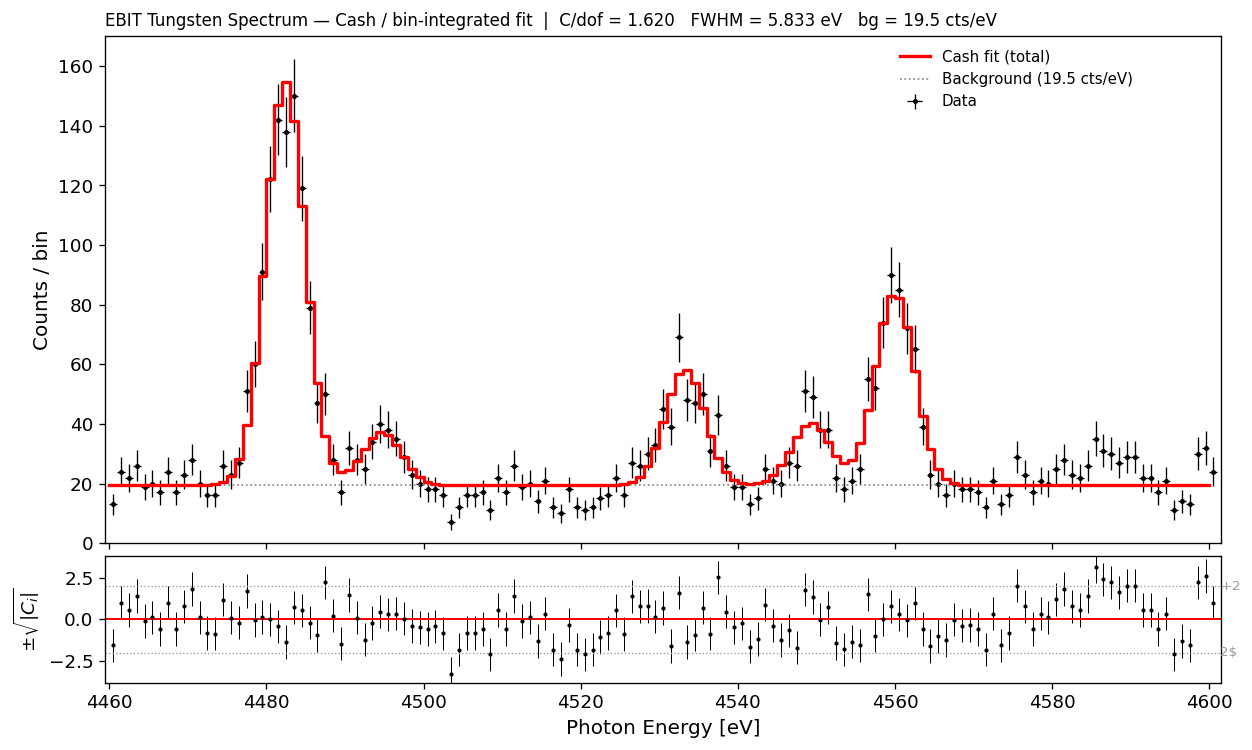

Saved: cash_fit_publication.pdf


In [ ]:
# ── Publication-quality fit plot: Cash / bin-integrated ────────────────────

p      = res_ca_int.params.valuesdict()
sigma  = p['sigma']
k_fwhm = 2.3548

# Evaluate best-fit model and components
best_model = eval_model(res_ca_int.params, binlow, binhigh, bincenters, binwidths, 'int')
components = [int_gauss_area(binlow, binhigh, p[f'ar{i}'], p[f'mu{i}'], sigma)
              for i in range(1, 6)]
bg_model   = int_bg(binlow, binhigh, p['bg'])
residuals  = signed_cash_resid_int(res_ca_int.params, observed, binlow, binhigh)

# Figure layout
fig = plt.figure(figsize=(12, 7))
gs  = gridspec.GridSpec(2, 1, height_ratios=[4, 1], hspace=0.04)
ax0 = fig.add_subplot(gs[0])
ax1 = fig.add_subplot(gs[1], sharex=ax0)

GCOLS = ['#1f77b4','#ff7f0e','#2ca02c','#9467bd','#8c564b']

# Data
ax0.errorbar(bincenters, observed, yerr=yerr, xerr=0.5,
             fmt='.', color='k', ms=4, elinewidth=0.8, zorder=5, label='Data')

# Total fit
ax0.step(binlow, best_model, where='post', color='red',
         lw=2.0, zorder=10, label='Cash fit (total)')

# Background
bg_val   = p['bg']
bg_label = f'Background ({bg_val:.1f} cts/eV)'
ax0.step(binlow, bg_model, where='post', color='gray',
         lw=1.0, ls=':', zorder=6, label=bg_label)

# Individual Gaussian components (plotted on top of background)
# for i, (comp, col) in enumerate(zip(components, GCOLS), 1):
#     mu_val = p[f'mu{i}']
#     ar_val = p[f'ar{i}']
#     lo1 = ci_dc_int[f'ar{i}']['bounds'][1][0] - ar_val
#     hi1 = ci_dc_int[f'ar{i}']['bounds'][1][1] - ar_val
#     glabel = f'G{i}  mu={mu_val:.2f} eV  A={ar_val:.0f} (+{hi1:.0f}/-{abs(lo1):.0f}) cts'
#     ax0.step(binlow, comp + bg_model, where='post',
#              color=col, lw=1.3, ls='--', alpha=0.85, zorder=7, label=glabel)

ax0.set_ylabel('Counts / bin', fontsize=12)
ax0.set_xlim(binlow[0] - 0.5, binhigh[-1] + 0.5)
ax0.set_ylim(bottom=0)

fwhm_val = sigma * k_fwhm
gof_str  = f'C/dof = {C_int/dof_ca_int:.3f}'
fwhm_str = f'FWHM = {fwhm_val:.3f} eV'
bg_str   = f'bg = {bg_val:.1f} cts/eV'
ax0.set_title(f'EBIT Tungsten Spectrum — Cash / bin-integrated fit  |  {gof_str}   {fwhm_str}   {bg_str}',
              fontsize=10, loc='left')
ax0.legend(fontsize=9, frameon=False, bbox_to_anchor=(0.70, 1.0), loc='upper left')
plt.setp(ax0.get_xticklabels(), visible=False)

# Residuals
ax1.errorbar(bincenters, residuals, yerr=1,
             fmt='.', color='k', ms=3, elinewidth=0.6)
ax1.axhline(0,  color='red',  lw=1.2)
ax1.axhline( 2, color='#999', ls=':', lw=0.8)
ax1.axhline(-2, color='#999', ls=':', lw=0.8)
ax1.set_ylabel(r'$\pm\sqrt{|C_i|}$', fontsize=11)
ax1.set_xlabel('Photon Energy [eV]', fontsize=12)
ax1.set_ylim(-3.8, 3.8)
ax1.text(binhigh[-1] + 0.4,  2.0, r'$+2$', fontsize=8, color='#999', va='center')
ax1.text(binhigh[-1] + 0.4, -2.0, r'2$', fontsize=8, color='#999', va='center')

plt.tight_layout()
plt.savefig('cash_fit_publication.pdf', bbox_inches='tight', dpi=150)
plt.show()
print(f'Saved: cash_fit_publication.pdf')


## 18. Voigt profile model — Cash / bin-integrated / ΔC profile

Comparison of the Gaussian model (section 11) against a **Voigt profile** model.

A Voigt profile is the convolution of a Gaussian (instrumental broadening, width σ)
and a Lorentzian (natural/Stark/pressure broadening, half-width γ).  It is the
physically correct line shape when both broadening mechanisms are present.

**Model parameterisation:**
- `area_i` — total counts in each line (same definition as Gaussian model)
- `mu_i` — line centre [eV]
- `sigma` — shared Gaussian width [eV] (instrumental)
- `gamma` — shared Lorentzian half-width [eV] (physical broadening)
- `bg` — flat background [counts/eV]

**Voigt FWHM** (Olivero & Longbothum approximation, accurate to 0.02%):

$$\text{FWHM}_V \approx 0.5346\, f_L + \sqrt{0.2166\, f_L^2 + f_G^2}$$

where $f_G = 2.3548\,\sigma$ and $f_L = 2\gamma$.

**Key comparison question:** Does adding a Lorentzian component (γ) significantly
improve the fit over the pure Gaussian model?  We compare C/dof and inspect whether
γ is constrained away from zero.


In [ ]:
from scipy.special import wofz
from scipy.integrate import quad

# ── Voigt profile (point-evaluated, used inside quad) ─────────────────────
def voigt_pt(x, area, mu, sigma, gamma):
    """Area-normalised Voigt profile evaluated at x.
    area  = total counts (integral over all x)
    sigma = Gaussian sigma [eV]
    gamma = Lorentzian half-width at half-maximum [eV]
    """
    z = ((x - mu) + 1j * gamma) / (sigma * np.sqrt(2))
    return area / (sigma * np.sqrt(2 * np.pi)) * np.real(wofz(z))

# ── Bin-integrated Voigt (fast Gauss-Legendre quadrature) ────────────────
def int_voigt(bl, bh, area, mu, sigma, gamma, n_sub=8):
    """Integrate Voigt profile over each bin using Gauss-Legendre quadrature.
    n_sub points per bin — machine-precision accurate, ~90x faster than scipy.quad.
    Returns array of counts per bin.
    """
    nodes, weights = np.polynomial.legendre.leggauss(n_sub)
    bl = np.asarray(bl, dtype=float); bh = np.asarray(bh, dtype=float)
    mid  = 0.5 * (bl + bh)
    half = 0.5 * (bh - bl)
    # Quadrature points: shape (n_bins, n_sub)
    x_pts = mid[:, None] + half[:, None] * nodes[None, :]
    z     = ((x_pts - mu) + 1j * gamma) / (sigma * np.sqrt(2))
    vals  = area / (sigma * np.sqrt(2 * np.pi)) * np.real(wofz(z))
    return np.dot(vals, weights) * half

# ── Voigt FWHM (Olivero & Longbothum / Kielkopf approximation) ───────────
def voigt_fwhm(sigma, gamma, dsigma=None, dgamma=None):
    """Voigt FWHM accurate to 0.02%.  Optionally propagate uncertainties."""
    fG   = 2.3548 * sigma     # Gaussian FWHM
    fL   = 2.0   * gamma      # Lorentzian FWHM
    fwhm = 0.5346 * fL + np.sqrt(0.2166 * fL**2 + fG**2)
    if dsigma is None or dgamma is None:
        return fwhm
    denom    = np.sqrt(0.2166 * fL**2 + fG**2)
    dF_dG    = fG / denom
    dF_dL    = 0.5346 + (0.2166 * fL) / denom
    dF_dsig  = dF_dG * 2.3548
    dF_dgam  = dF_dL * 2.0
    dfwhm    = np.sqrt((dF_dsig * dsigma)**2 + (dF_dgam * dgamma)**2)
    return fwhm, dfwhm

# ── 5-Voigt + background model (shared sigma and gamma) ───────────────────
def model5_voigt(bl, bh, ar1,mu1, ar2,mu2, ar3,mu3, ar4,mu4, ar5,mu5,
                 sigma, gamma, bg):
    """Bin-integrated 5-Voigt model. sigma and gamma shared across all lines."""
    m = int_bg(bl, bh, bg)
    for ar, mu in [(ar1,mu1),(ar2,mu2),(ar3,mu3),(ar4,mu4),(ar5,mu5)]:
        m = m + int_voigt(bl, bh, ar, mu, sigma, gamma)
    return m

def eval_model_voigt(params, bl, bh):
    p = params.valuesdict()
    return model5_voigt(bl, bh,
                        p['ar1'],p['mu1'], p['ar2'],p['mu2'],
                        p['ar3'],p['mu3'], p['ar4'],p['mu4'],
                        p['ar5'],p['mu5'], p['sigma'], p['gamma'], p['bg'])

print("Voigt functions defined.")
print("  voigt_pt        : area-normalised Voigt evaluated at x")
print("  int_voigt       : bin-integrated Voigt via scipy.quad")
print("  voigt_fwhm      : Olivero-Longbothum FWHM approximation")
print("  model5_voigt    : 5-Voigt + background, shared sigma and gamma")


Voigt functions defined.
  voigt_pt        : area-normalised Voigt evaluated at x
  int_voigt       : bin-integrated Voigt via scipy.quad
  voigt_fwhm      : Olivero-Longbothum FWHM approximation
  model5_voigt    : 5-Voigt + background, shared sigma and gamma


In [ ]:
# ── Cash statistic for Voigt model ───────────────────────────────────────
def cash_array_voigt(params, ydata, bl, bh):
    """Per-bin Cash array for 5-Voigt bin-integrated model."""
    model = eval_model_voigt(params, bl, bh)
    model = np.where(model <= 0, 1e-300, model)
    d     = np.where(ydata  <= 0, 1e-10,  ydata)
    return -2.0 * ((d - model) + d * (np.log(model) - np.log(d)))

def cash_scalar_voigt(params, ydata, bl, bh):
    return kahanSum(cash_array_voigt(params, ydata, bl, bh))

def signed_cash_resid_voigt(params, ydata, bl, bh):
    arr   = cash_array_voigt(params, ydata, bl, bh)
    model = eval_model_voigt(params, bl, bh)
    return np.sign(ydata - model) * np.sqrt(np.abs(arr))

print("Voigt Cash objectives defined.")


Voigt Cash objectives defined.


In [ ]:
def make_params_voigt(gauss_result=None):
    """
    Initial parameters for 5-Voigt model.
    Seeded from Gaussian best-fit if provided (warm start).
    gamma starts small — if data are purely Gaussian, gamma → 0.
    """
    p = Parameters()
    # Seed areas and centres from Gaussian fit if available
    if gauss_result is not None:
        gp = gauss_result.params.valuesdict()
        for i in range(1, 6):
            p.add(f'ar{i}', value=gp[f'ar{i}'], min=0,    max=5000)
            p.add(f'mu{i}', value=gp[f'mu{i}'],
                  min=gp[f'mu{i}']-2, max=gp[f'mu{i}']+2)
        p.add('sigma', value=gp['sigma'], min=0.1, max=5.0)
        p.add('bg',    value=gp['bg'],    min=5,   max=50)
    else:
        p.add('ar1', value=600,    min=0, max=5000)
        p.add('ar2', value=120,    min=0, max=1500)
        p.add('ar3', value=200,    min=0, max=2000)
        p.add('ar4', value=150,    min=0, max=2000)
        p.add('ar5', value=350,    min=0, max=2000)
        p.add('mu1', value=4482.5, min=4479, max=4486)
        p.add('mu2', value=4494.0, min=4490, max=4498)
        p.add('mu3', value=4532.0, min=4528, max=4536)
        p.add('mu4', value=4548.0, min=4544, max=4552)
        p.add('mu5', value=4558.5, min=4554, max=4563)
        p.add('sigma', value=1.5, min=0.1, max=5.0)
        p.add('bg',    value=21.0, min=5,   max=50)
    # gamma: start small, allow up to ~2 eV Lorentzian half-width
    p.add('gamma', value=0.3, min=1e-4, max=3.0)
    return p

p_voigt = make_params_voigt(gauss_result=res_ca_int)
n_free  = sum(v.vary for v in p_voigt.values())
print(f"Voigt model parameters: {n_free} free")
print("  ar1-ar5  : areas [counts]")
print("  mu1-mu5  : line centres [eV]")
print("  sigma    : shared Gaussian width [eV]  (instrumental)")
print("  gamma    : shared Lorentzian half-width [eV]  (physical)")
print("  bg       : background [counts/eV]")
print()
print(f"  Gaussian model had {sum(v.vary for v in res_ca_int.params.values())} free params")
print(f"  Voigt adds 1 extra (gamma):  {n_free} free params")


Voigt model parameters: 13 free
  ar1-ar5  : areas [counts]
  mu1-mu5  : line centres [eV]
  sigma    : shared Gaussian width [eV]  (instrumental)
  gamma    : shared Lorentzian half-width [eV]  (physical)
  bg       : background [counts/eV]

  Gaussian model had 12 free params
  Voigt adds 1 extra (gamma):  13 free params


In [ ]:
print("Fitting Voigt model (Cash / bin-integrated) ...")
print("Note: int_voigt uses scipy.quad per bin — slower than Gaussian erf.")
print()

kw_voigt = dict(fcn_args=(observed, binlow, binhigh), reduce_fcn=kahanSum)

# Stage 1: Nelder-Mead (gradient-free global search)
print("  Stage 1: Nelder-Mead ...", end=' ', flush=True)
r_nm_v = Minimizer(cash_array_voigt, make_params_voigt(res_ca_int),
                   **kw_voigt).minimize(method='nelder')
print(f"done   C = {cash_scalar_voigt(r_nm_v.params, observed, binlow, binhigh):.2f}")

# Stage 2: L-BFGS-B refinement
print("  Stage 2: L-BFGS-B ...", end=' ', flush=True)
mini_voigt = Minimizer(cash_array_voigt, r_nm_v.params, **kw_voigt)
res_voigt  = mini_voigt.minimize(method='lbfgsb')
C_voigt    = cash_scalar_voigt(res_voigt.params, observed, binlow, binhigh)
dof_voigt  = len(observed) - sum(p.vary for p in res_voigt.params.values())
print(f"done   C = {C_voigt:.2f}")

print()
pv = res_voigt.params.valuesdict()
print(f"Best-fit parameters:")
print(f"  sigma  = {pv['sigma']:.4f} eV   (Gaussian width)")
print(f"  gamma  = {pv['gamma']:.4f} eV   (Lorentzian half-width)")
fwhm_v = voigt_fwhm(pv['sigma'], pv['gamma'])
print(f"  Voigt FWHM = {fwhm_v:.4f} eV")
print()
print(f"  C/dof  (Voigt)    = {C_voigt/dof_voigt:.4f}  (dof={dof_voigt})")
print(f"  C/dof  (Gaussian) = {C_int/dof_ca_int:.4f}  (dof={dof_ca_int})")
print()
delta_C = C_int - C_voigt
print(f"  Delta-C = C(Gaussian) - C(Voigt) = {delta_C:.3f}")
print(f"  Extra free parameter: 1 (gamma)")
print(f"  Wilks p-value for improvement: chi2.sf({delta_C:.3f}, 1) = "
      f"{chi2_dist.sf(delta_C, 1):.4f}")
print()
if delta_C > 9.0:
    print("  Delta-C > 9  -> Voigt improvement is >3-sigma significant")
elif delta_C > 4.0:
    print("  Delta-C > 4  -> Voigt improvement is 2-3 sigma significant")
elif delta_C > 1.0:
    print("  Delta-C > 1  -> Voigt improvement is 1-2 sigma significant")
else:
    print("  Delta-C < 1  -> Voigt improvement is NOT statistically significant")
    print("  The Gaussian model is adequate; gamma is not required by the data.")


Fitting Voigt model (Cash / bin-integrated) ...
Note: int_voigt uses scipy.quad per bin — slower than Gaussian erf.

  Stage 1: Nelder-Mead ... done   C = 209.00
  Stage 2: L-BFGS-B ... done   C = 208.99

Best-fit parameters:
  sigma  = 2.4771 eV   (Gaussian width)
  gamma  = 0.0001 eV   (Lorentzian half-width)
  Voigt FWHM = 5.8332 eV

  C/dof  (Voigt)    = 1.6328  (dof=128)
  C/dof  (Gaussian) = 1.6201  (dof=129)

  Delta-C = C(Gaussian) - C(Voigt) = -0.001
  Extra free parameter: 1 (gamma)
  Wilks p-value for improvement: chi2.sf(-0.001, 1) = 1.0000

  Delta-C < 1  -> Voigt improvement is NOT statistically significant
  The Gaussian model is adequate; gamma is not required by the data.


In [ ]:
print("Computing Voigt Hessian stderr (for scan grid sizing) ...", end=' ', flush=True)
se_voigt = hessian_stderr(res_voigt, cash_scalar_voigt,
                           (observed, binlow, binhigh))
for n, s in se_voigt.items():
    res_voigt.params[n].stderr = s
print("done")
print()
for n, s in se_voigt.items():
    print(f"  {n:8s}  stderr = {s:.5f}")


Computing Voigt Hessian stderr (for scan grid sizing) ... done

  ar1       stderr = 32.77272
  mu1       stderr = 0.11259
  ar2       stderr = 17.17515
  mu2       stderr = 0.48697
  ar3       stderr = 21.11837
  mu3       stderr = 0.29321
  ar4       stderr = 17.54096
  mu4       stderr = 0.36947
  ar5       stderr = 24.48338
  mu5       stderr = 0.17125
  sigma     stderr = 0.07043
  bg        stderr = 0.41678
  gamma     stderr = 0.00436


In [ ]:
SCAN_VOIGT = ['mu1','mu2','mu3','mu4','mu5',
              'ar1','ar2','ar3','ar4','ar5',
              'sigma','gamma','bg']

print("Running ΔC profile scans for Voigt model ...")
print("(Fast Gauss-Legendre quadrature: ~3-5 min total)")
ci_voigt = {}
for pname in SCAN_VOIGT:
    print(f"  {pname}", end=" ", flush=True)
    # Use 40-point grid (sufficient for smooth profiles)
    v = res_voigt.params[pname].value
    s = res_voigt.params[pname].stderr or abs(v)*0.02
    grid = np.linspace(v - 4*s, v + 4*s, 40)
    _, dc, bnd = profile_scan(cash_scalar_voigt, cash_array_voigt,
                               pname, grid, res_voigt,
                               (observed, binlow, binhigh), use_cash=True)
    ci_voigt[pname] = {"grid": grid, "dc": dc, "bounds": bnd}
    print("done")
print("Complete.")


Running ΔC profile scans for Voigt model ...
(Fast Gauss-Legendre quadrature: ~3-5 min total)
  mu1 done
  mu2 done
  mu3 done
  mu4 done
  mu5 done
  ar1 done
  ar2 done
  ar3 done
  ar4 done
  ar5 done
  sigma done
  gamma done
  bg done
Complete.


In [ ]:
# ── Publication table: Voigt / Cash / bin-integrated / ΔC profile ─────────
pv = res_voigt.params.valuesdict()

VOIGT_LINE_LABELS = {
    'mu1': 'G1 centre [eV]',
    'mu2': 'G2 centre [eV]',
    'mu3': 'G3 centre [eV]',
    'mu4': 'G4 centre [eV]',
    'mu5': 'G5 centre [eV]',
    'ar1': 'G1 area [cts]',
    'ar2': 'G2 area [cts]',
    'ar3': 'G3 area [cts]',
    'ar4': 'G4 area [cts]',
    'ar5': 'G5 area [cts]',
}

print("Voigt model — Cash statistic / bin-integrated / ΔC profile scan")
print("Method: Nelder-Mead → L-BFGS-B minimisation of C = -2Σ[(d-m) + d·ln(m/d)]")
print(f"C/dof = {C_voigt/dof_voigt:.3f}   (N bins = {len(observed)}, free params = {len(observed)-dof_voigt})")
print()

w = 14
print(f"  {'Parameter':<22s}  {'Best fit':>{w}s}  "
      f"{'−1σ':>{w}s}  {'+1σ':>{w}s}  "
      f"{'−2σ':>{w}s}  {'+2σ':>{w}s}")
print("  " + "─"*(22 + 5*w + 8))

for pname, label in VOIGT_LINE_LABELS.items():
    best = res_voigt.params[pname].value
    lo1  = ci_voigt[pname]['bounds'][1][0] - best
    hi1  = ci_voigt[pname]['bounds'][1][1] - best
    lo2  = ci_voigt[pname]['bounds'][2][0] - best
    hi2  = ci_voigt[pname]['bounds'][2][1] - best
    print(f"  {label:<22s}  {best:{w}.4f}  "
          f"{lo1:{w}.4f}  {hi1:+{w}.4f}  "
          f"{lo2:{w}.4f}  {hi2:+{w}.4f}")

print("  " + "─"*(22 + 5*w + 8))

# sigma (Gaussian width)
best_sig = pv['sigma']
lo1s = ci_voigt['sigma']['bounds'][1][0] - best_sig
hi1s = ci_voigt['sigma']['bounds'][1][1] - best_sig
lo2s = ci_voigt['sigma']['bounds'][2][0] - best_sig
hi2s = ci_voigt['sigma']['bounds'][2][1] - best_sig
print(f"  {'Gaussian sigma [eV]':<22s}  {best_sig:{w}.4f}  "
      f"{lo1s:{w}.4f}  {hi1s:+{w}.4f}  "
      f"{lo2s:{w}.4f}  {hi2s:+{w}.4f}")

# gamma (Lorentzian half-width)
best_gam = pv['gamma']
lo1g = ci_voigt['gamma']['bounds'][1][0] - best_gam
hi1g = ci_voigt['gamma']['bounds'][1][1] - best_gam
lo2g = ci_voigt['gamma']['bounds'][2][0] - best_gam
hi2g = ci_voigt['gamma']['bounds'][2][1] - best_gam
print(f"  {'Lorentzian gamma [eV]':<22s}  {best_gam:{w}.4f}  "
      f"{lo1g:{w}.4f}  {hi1g:+{w}.4f}  "
      f"{lo2g:{w}.4f}  {hi2g:+{w}.4f}")

# Voigt FWHM with propagated uncertainty from profile bounds
sig_hi = ci_voigt['sigma']['bounds'][1][1]
sig_lo = ci_voigt['sigma']['bounds'][1][0]
gam_hi = ci_voigt['gamma']['bounds'][1][1]
gam_lo = ci_voigt['gamma']['bounds'][1][0]
fwhm_best       = voigt_fwhm(best_sig, best_gam)
fwhm_hi_approx  = voigt_fwhm(sig_hi, gam_hi) - fwhm_best
fwhm_lo_approx  = voigt_fwhm(sig_lo, gam_lo) - fwhm_best
print(f"  {'Voigt FWHM [eV]':<22s}  {fwhm_best:{w}.4f}  "
      f"{fwhm_lo_approx:{w}.4f}  {fwhm_hi_approx:+{w}.4f}  "
      f"{'':>{w}s}  {'':>{w}s}")

# Background
best_bg = pv['bg']
lo1b = ci_voigt['bg']['bounds'][1][0] - best_bg
hi1b = ci_voigt['bg']['bounds'][1][1] - best_bg
lo2b = ci_voigt['bg']['bounds'][2][0] - best_bg
hi2b = ci_voigt['bg']['bounds'][2][1] - best_bg
print(f"  {'Background [cts/eV]':<22s}  {best_bg:{w}.4f}  "
      f"{lo1b:{w}.4f}  {hi1b:+{w}.4f}  "
      f"{lo2b:{w}.4f}  {hi2b:+{w}.4f}")

print()
print(f"  Notes:")
print(f"    sigma = Gaussian (instrumental) width; gamma = Lorentzian half-width")
print(f"    Voigt FWHM uncertainty estimated from profile bounds on sigma and gamma.")
print(f"    Confidence intervals from ΔC profile scan, Wilks thresholds:")
print(f"      1σ: ΔC = 1.000   2σ: ΔC = 4.000")


Voigt model — Cash statistic / bin-integrated / ΔC profile scan
Method: Nelder-Mead → L-BFGS-B minimisation of C = -2Σ[(d-m) + d·ln(m/d)]
C/dof = 1.633   (N bins = 141, free params = 13)

  Parameter                     Best fit             −1σ             +1σ             −2σ             +2σ
  ────────────────────────────────────────────────────────────────────────────────────────────────────
  G1 centre [eV]               4482.3594         -0.1121         +0.1121         -0.2252         +0.2251
  G2 centre [eV]               4494.6718         -0.4895         +0.4833         -1.0031         +0.9741
  G3 centre [eV]               4533.2446         -0.2926         +0.2910         -0.5903         +0.5845
  G4 centre [eV]               4549.2918         -0.3706         +0.3694         -0.7510         +0.7466
  G5 centre [eV]               4559.9436         -0.1706         +0.1708         -0.3430         +0.3435
  G1 area [cts]                 846.7168        -33.7246        +34.4397       

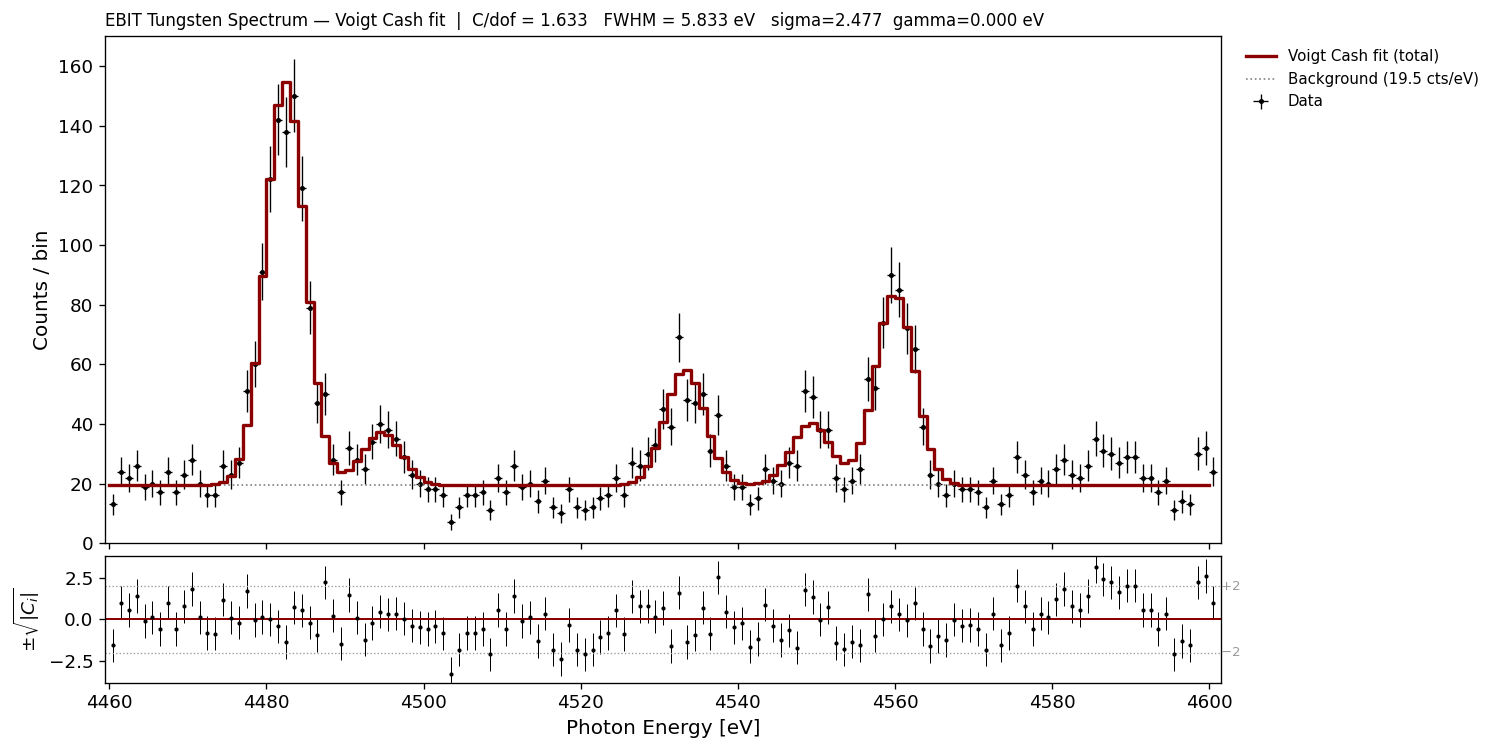

Saved: voigt_fit_publication.pdf


In [ ]:
# ── Publication-quality fit plot: Voigt / Cash / bin-integrated ─────────
pv    = res_voigt.params.valuesdict()
sigma = pv['sigma']
gamma = pv['gamma']

best_model_v = eval_model_voigt(res_voigt.params, binlow, binhigh)
components_v = [int_voigt(binlow, binhigh, pv[f'ar{i}'], pv[f'mu{i}'],
                           sigma, gamma) for i in range(1, 6)]
bg_model_v   = int_bg(binlow, binhigh, pv['bg'])
residuals_v  = signed_cash_resid_voigt(res_voigt.params, observed, binlow, binhigh)
fwhm_v       = voigt_fwhm(sigma, gamma)

fig = plt.figure(figsize=(12, 7))
gs  = gridspec.GridSpec(2, 1, height_ratios=[4, 1], hspace=0.04)
ax0 = fig.add_subplot(gs[0])
ax1 = fig.add_subplot(gs[1], sharex=ax0)

GCOLS = ['#1f77b4','#ff7f0e','#2ca02c','#9467bd','#8c564b']

ax0.errorbar(bincenters, observed, yerr=yerr, xerr=0.5,
             fmt='.', color='k', ms=4, elinewidth=0.8, zorder=5, label='Data')
ax0.step(binlow, best_model_v, where='post', color='darkred',
         lw=2.0, zorder=10, label='Voigt Cash fit (total)')
bg_val_v = pv['bg']
ax0.step(binlow, bg_model_v, where='post', color='gray',
         lw=1.0, ls=':', zorder=6,
         label=f'Background ({bg_val_v:.1f} cts/eV)')

# for i, (comp, col) in enumerate(zip(components_v, GCOLS), 1):
#     ar_val  = pv[f'ar{i}']
#     mu_val  = pv[f'mu{i}']
#     lo1v = ci_voigt[f'ar{i}']['bounds'][1][0] - ar_val
#     hi1v = ci_voigt[f'ar{i}']['bounds'][1][1] - ar_val
#     glabel = f'V{i}  mu={mu_val:.2f} eV  A={ar_val:.0f} (+{hi1v:.0f}/-{abs(lo1v):.0f}) cts'
#     ax0.step(binlow, comp + bg_model_v, where='post',
#              color=col, lw=1.3, ls='--', alpha=0.85, zorder=7, label=glabel)

ax0.set_ylabel('Counts / bin', fontsize=12)
ax0.set_xlim(binlow[0] - 0.5, binhigh[-1] + 0.5)
ax0.set_ylim(bottom=0)
gof_str_v  = f'C/dof = {C_voigt/dof_voigt:.3f}'
fwhm_str_v = f'FWHM = {fwhm_v:.3f} eV'
sig_str_v  = f'sigma={sigma:.3f}  gamma={gamma:.3f} eV'
ax0.set_title(f'EBIT Tungsten Spectrum — Voigt Cash fit  |  {gof_str_v}   {fwhm_str_v}   {sig_str_v}',
              fontsize=10, loc='left')
ax0.legend(fontsize=9, frameon=False, bbox_to_anchor=(1.01, 1.0), loc='upper left')
plt.setp(ax0.get_xticklabels(), visible=False)

ax1.errorbar(bincenters, residuals_v, yerr=1,
             fmt='.', color='k', ms=3, elinewidth=0.6)
ax1.axhline(0,  color='darkred', lw=1.2)
ax1.axhline( 2, color='#999',    ls=':', lw=0.8)
ax1.axhline(-2, color='#999',    ls=':', lw=0.8)
ax1.set_ylabel(r'$\pm\sqrt{|C_i|}$', fontsize=11)
ax1.set_xlabel('Photon Energy [eV]', fontsize=12)
ax1.set_ylim(-3.8, 3.8)
ax1.text(binhigh[-1] + 0.4,  2.0, r'$+2$', fontsize=8, color='#999', va='center')
ax1.text(binhigh[-1] + 0.4, -2.0, r'$-2$', fontsize=8, color='#999', va='center')

plt.tight_layout()
plt.savefig('voigt_fit_publication.pdf', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: voigt_fit_publication.pdf')


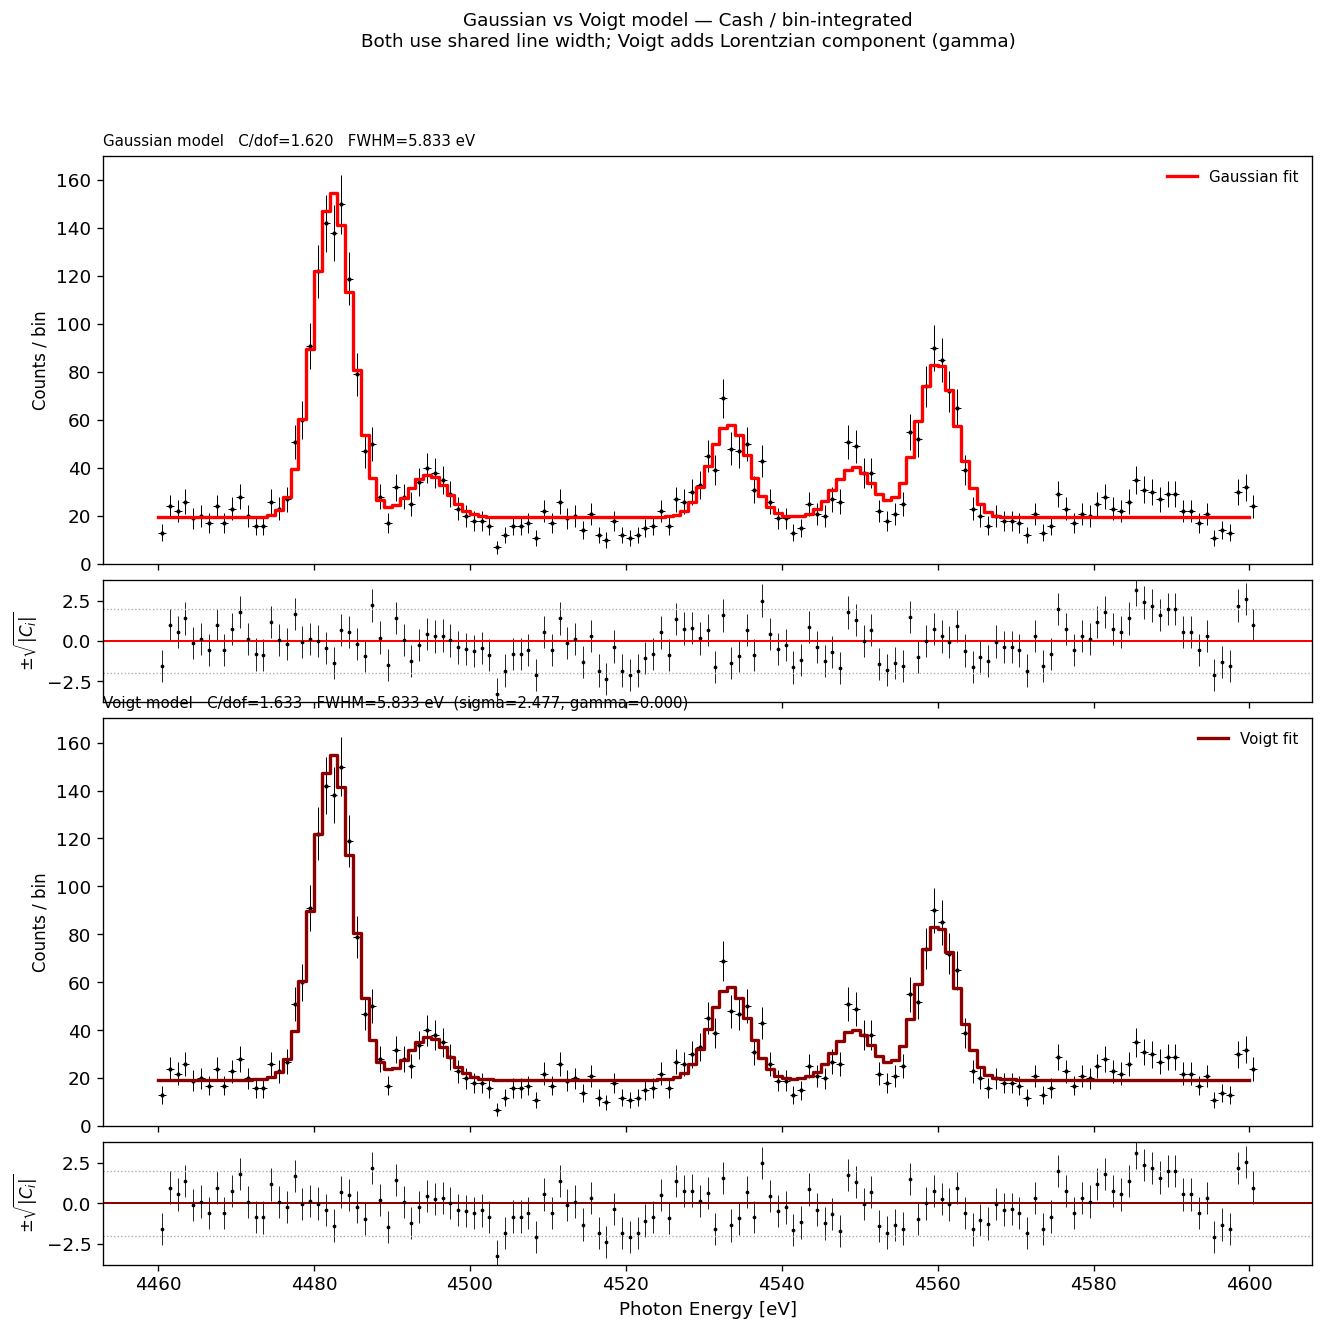

Saved: gaussian_vs_voigt_comparison.pdf  and  gaussian_vs_voigt_comparison.png

────────────────────────────────────────────────────────────
Model comparison summary
────────────────────────────────────────────────────────────
  Gaussian  C/dof = 1.6201   FWHM = 5.8333 eV
  Voigt     C/dof = 1.6328   FWHM = 5.8332 eV
             sigma = 2.4771 eV   gamma = 0.0001 eV

  Delta-C = -0.001  (1 extra dof = gamma)
  Wilks p-value = 1.0000
  Significance: <1σ  →  Gaussian adequate, gamma not needed


In [ ]:
# ── Side-by-side Gaussian vs Voigt residual comparison ────────────────────
gauss_resid = signed_cash_resid_int(res_ca_int.params, observed, binlow, binhigh)
voigt_resid = signed_cash_resid_voigt(res_voigt.params, observed, binlow, binhigh)
best_model_g = eval_model(res_ca_int.params, binlow, binhigh, bincenters, binwidths, 'int')

fig, axes = plt.subplots(4, 1, figsize=(13, 12),
    gridspec_kw={'height_ratios': [4, 1.2, 4, 1.2], 'hspace': 0.06})

for ax_idx, (result, model, resid, col, lbl, gof, extra) in enumerate([
    (res_ca_int, best_model_g, gauss_resid, 'red',
     'Gaussian', f'C/dof={C_int/dof_ca_int:.3f}',
     f'FWHM={res_ca_int.params["sigma"].value*2.3548:.3f} eV'),
    (res_voigt, best_model_v, voigt_resid, 'darkred',
     'Voigt', f'C/dof={C_voigt/dof_voigt:.3f}',
     f'FWHM={fwhm_v:.3f} eV  (sigma={pv["sigma"]:.3f}, gamma={pv["gamma"]:.3f})'),
]):
    ax_main = axes[ax_idx * 2]
    ax_res  = axes[ax_idx * 2 + 1]

    ax_main.errorbar(bincenters, observed, yerr=yerr, xerr=0.5,
                     fmt='.', color='k', ms=3, elinewidth=0.6, zorder=5)
    ax_main.step(binlow, model, where='post', color=col, lw=2, zorder=10,
                 label=f'{lbl} fit')
    ax_main.set_ylabel('Counts / bin', fontsize=10)
    ax_main.set_title(f'{lbl} model   {gof}   {extra}',
                      fontsize=9, loc='left')
    ax_main.set_ylim(bottom=0)
    ax_main.legend(fontsize=9, frameon=False, loc='upper right')
    plt.setp(ax_main.get_xticklabels(), visible=False)

    ax_res.errorbar(bincenters, resid, yerr=1,
                    fmt='.', color='k', ms=2.5, elinewidth=0.5)
    ax_res.axhline(0,  color=col,  lw=1.2)
    ax_res.axhline( 2, color='#aaa', ls=':', lw=0.8)
    ax_res.axhline(-2, color='#aaa', ls=':', lw=0.8)
    ax_res.set_ylabel(r'$\pm\sqrt{|C_i|}$', fontsize=10)
    ax_res.set_ylim(-3.8, 3.8)
    if ax_idx == 1:
        ax_res.set_xlabel('Photon Energy [eV]', fontsize=11)
    else:
        plt.setp(ax_res.get_xticklabels(), visible=False)

# Share x axis
for ax in axes[1:]:
    ax.sharex(axes[0])

fig.suptitle('Gaussian vs Voigt model — Cash / bin-integrated\n'
             'Both use shared line width; Voigt adds Lorentzian component (gamma)',
             fontsize=11)
plt.tight_layout()
plt.savefig('gaussian_vs_voigt_comparison.pdf', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: gaussian_vs_voigt_comparison.pdf')

# ── Summary numbers ────────────────────────────────────────────────────────
print()
print("─"*60)
print("Model comparison summary")
print("─"*60)
pg = res_ca_int.params.valuesdict()
print(f"  Gaussian  C/dof = {C_int/dof_ca_int:.4f}   FWHM = {pg['sigma']*2.3548:.4f} eV")
print(f"  Voigt     C/dof = {C_voigt/dof_voigt:.4f}   FWHM = {fwhm_v:.4f} eV")
print(f"             sigma = {pv['sigma']:.4f} eV   gamma = {pv['gamma']:.4f} eV")
print()
dC = C_int - C_voigt
from scipy.stats import chi2 as chi2_dist
pval = chi2_dist.sf(dC, 1)
print(f"  Delta-C = {dC:.3f}  (1 extra dof = gamma)")
print(f"  Wilks p-value = {pval:.4f}")
if dC > 9:
    sig = '>3σ'; verdict = 'Voigt significantly preferred'
elif dC > 4:
    sig = '2-3σ'; verdict = 'Voigt marginally preferred'
elif dC > 1:
    sig = '1-2σ'; verdict = 'Marginal improvement, not significant'
else:
    sig = '<1σ'; verdict = 'Gaussian adequate, gamma not needed'
print(f"  Significance: {sig}  →  {verdict}")
